# Imports

In [1]:
import os
from datetime import datetime

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
sns.set_theme("talk")

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.callbacks import ModelCheckpoint, TensorBoard, EarlyStopping

from tqdm.notebook import tqdm
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, normalize
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
import eli5
from eli5.sklearn import PermutationImportance
import shap


from tensorflow.keras.regularizers import l2
from tensorflow.keras.regularizers import l1
from scipy import stats

import itertools


# Predicting Exploded

In [2]:
progenitor = pd.read_csv('progs_sukhbold_2016_new.csv')

In [3]:
progenitor = progenitor.iloc[:,7:]

In [4]:
progenitor['exploded'] = pd.read_csv('table.csv')['exploded']

In [5]:
progenitor

,xi_3.0,coremass_Si,coremass_Fe,corerad_Si,corerad_Fe,exploded
0,0.000036,1.319596,1.319596,1.385851e+08,1.385851e+08,True
1,0.000042,1.343052,1.290904,1.469831e+08,1.067884e+08,True
2,0.000048,1.357887,1.302871,1.519480e+08,1.088876e+08,True
3,0.000056,1.396045,1.300979,1.832699e+08,1.090382e+08,True
4,0.000051,1.415957,1.343002,1.644623e+08,1.193591e+08,True
...,...,...,...,...,...,...
195,0.138267,1.587106,1.457770,2.027432e+08,1.470957e+08,True
196,0.180592,1.719733,1.503255,2.360583e+08,1.525284e+08,True
197,0.166606,1.658498,1.482070,2.232799e+08,1.509100e+08,True
198,0.188312,1.801763,1.538623,2.797782e+08,1.639150e+08,True


# Predicting exploded

In [6]:
progenitor['exploded'] = progenitor['exploded'].astype(int)


In [7]:
Y = np.asarray(progenitor['exploded'])

In [8]:
progenitor = progenitor.drop(columns=['exploded'])

In [9]:
X = np.asarray(progenitor) #needs to be an array for tensorflow later on

In [10]:
# Preprocess the data (normalize)
X_nn = X.copy()
# X_nn[:,0] = np.log(X_nn[:,0])
# X_nn[:,4] = np.exp(X_nn[:,4])

# Perform the Box-Cox transformation to normalize
transformed_column3, lambda_value3 = stats.boxcox(X_nn[:,0])
transformed_columnms, lambda_valuems = stats.boxcox(X_nn[:,1])
transformed_columnmf, lambda_valuemf = stats.boxcox(X_nn[:,2])
transformed_columnrs, lambda_valuers = stats.boxcox(X_nn[:,3])
transformed_columnrf, lambda_valuerf = stats.boxcox(X_nn[:,4])


# Update the transformed column in X_nn
X_nn[:,0] = transformed_column3
X_nn[:,1] = transformed_columnms
X_nn[:,2] = transformed_columnmf
X_nn[:,3] = transformed_columnrs
X_nn[:,4] = transformed_columnrf

X_mean = X_nn.mean(axis=0)
X_std = X_nn.std(axis=0)

X_nn = (X_nn - X_mean) / (X_std)

Y_nn = Y.copy()
Y_mean = Y_nn.mean(axis=0)
Y_std = Y_nn.std(axis=0)

Y_nn = (Y_nn - Y_mean) / (Y_std)

In [11]:
(X_train, 
 X_val,
 Y_train,
 Y_val) = train_test_split(X_nn, Y_nn, train_size=0.7, shuffle=True)

In [12]:
print(X_train.shape)
print(Y_train.shape)
print(X_val.shape)
print(Y_val.shape)

(140, 5)
(140,)
(60, 5)
(60,)


# Building the model.

In [13]:
# Build the model
beta = 0
model = Sequential()
model.add(Dense(64, input_dim=X_nn.shape[1], activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
model.add(Dropout(.2))
model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
model.add(Dropout(.2))
model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
model.add(Dropout(.2))
model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
model.add(Dropout(.2))
model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
model.add(Dropout(.2))
model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
model.add(Dropout(.2))

model.add(Dense(1, activation='linear', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta)))

model.compile(loss='mean_squared_error', optimizer='adam')
print(model.summary())

Model: "sequential"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
dense (Dense)                (None, 64)                384       
_________________________________________________________________
dropout (Dropout)            (None, 64)                0         
_________________________________________________________________
dense_1 (Dense)              (None, 64)                4160      
_________________________________________________________________
dropout_1 (Dropout)          (None, 64)                0         
_________________________________________________________________
dense_2 (Dense)              (None, 64)                4160      
_________________________________________________________________
dropout_2 (Dropout)          (None, 64)                0         
_________________________________________________________________
dense_3 (Dense)              (None, 64)                4

In [14]:
def train(model, X_train, Y_train, X_val, Y_val, **kwargs):
    
    X_train = tf.convert_to_tensor(X_train)
    Y_train = tf.convert_to_tensor(Y_train)
    Train = (X_train, Y_train)

    X_val = tf.convert_to_tensor(X_val)
    Y_val = tf.convert_to_tensor(Y_val)
    Val = (X_val, Y_val)
    
    cur_date_str = datetime.now().strftime("%Y-%m-%dT%H-%M-%S")
    logdir="logs/scalars/" + cur_date_str
    tensorboard_callback = TensorBoard(log_dir=logdir)
    checkpoints_dir = os.path.join('checkpoints', cur_date_str)
    os.makedirs(checkpoints_dir, exist_ok=True)
    checkpointer_best = ModelCheckpoint(monitor='val_loss', 
                                        filepath=os.path.join(checkpoints_dir, 'grid_weights_best.h5'), 
                                        save_best_only=True, save_weights_only=True)
    early_stopping = EarlyStopping(monitor='val_loss', 
                                   min_delta=0, patience=500, 
                                   verbose=0, mode='auto', baseline=None, 
                                   restore_best_weights=True)
    fit_kwargs = dict(validation_data=Val, 
                  epochs=400000, batch_size=8,
                  callbacks=[checkpointer_best, tensorboard_callback, early_stopping], 
                  verbose=0)
    fit_kwargs.update(kwargs)

    model.fit(*Train, **fit_kwargs)

In [15]:
# %%time
# train(model, X_train, Y_train, X_val, Y_val, verbose = 1)

In [16]:
# #https://machinelearningmastery.com/display-deep-learning-model-training-history-in-keras/
# plt.figure(dpi=150)
# plt.plot(model.history.history['loss'])
# plt.plot(model.history.history['val_loss'])
# plt.title('model loss')
# plt.ylabel('loss')
# plt.xlabel('epoch')
# plt.legend(['train', 'val'])
# plt.yscale("log")
# plt.show()

In [17]:
# # get the neural networks prediction (with validation dataset)
# Y_nn_test = model(X_val, training = False)
# Y_emu_test = np.exp(Y_std * Y_nn_test + Y_mean) - 1e-5

In [18]:
# Y_emu_test = (Y_emu_test-np.min(Y_emu_test))/(np.max(Y_emu_test)-np.min(Y_emu_test))
# Y_val = (Y_val-np.min(Y_val))/(np.max(Y_val)-np.min(Y_val))

In [19]:
# for i, man in enumerate(Y_emu_test):
#     if man >=0.5:
#         Y_emu_test[i]=1
#     else:
#         Y_emu_test[i]=0

In [20]:
# accuracy_score(Y_val, Y_emu_test)

In [21]:
# accuracy = [0.9166666666666666,
#             0.9666666666666667,
#             0.95,
#             0.95,
#             0.9833333333333333,
#             0.9666666666666667,
#             0.9833333333333333,
#             1.0,
#             0.9833333333333333,
#             0.9833333333333333,
#             0.9333333333333333,
#             0.9833333333333333
#            ]
# print('Average Accuracy->')
# print(np.average(accuracy))


In [22]:
# cm = confusion_matrix(Y_val,Y_emu_test)
# sns.heatmap(cm, annot=True, cmap='Blues', fmt='g')
# plt.xlabel('Predicted')
# plt.ylabel('True')
# plt.title('Confusion Matrix')

# plt.show()


# Using the above model on single columns:

In [15]:
progs = pd.read_csv('progs_sukhbold_2016_new.csv')
progs

,zams,xi_1.5,xi_1.75,xi_2.0,xi_2.25,xi_2.5,xi_2.75,xi_3.0,coremass_Si,coremass_Fe,corerad_Si,corerad_Fe
0,9.00,0.005255,0.000067,0.000047,0.000041,0.000038,0.000037,0.000036,1.319596,1.319596,1.385851e+08,1.385851e+08
1,9.25,0.028243,0.002541,0.000075,0.000054,0.000047,0.000044,0.000042,1.343052,1.290904,1.469831e+08,1.067884e+08
2,9.50,0.093333,0.008571,0.002250,0.000091,0.000062,0.000053,0.000048,1.357887,1.302871,1.519480e+08,1.088876e+08
3,9.75,0.304821,0.013190,0.005737,0.002271,0.000104,0.000067,0.000056,1.396045,1.300979,1.832699e+08,1.090382e+08
4,10.00,0.454843,0.017038,0.007223,0.003974,0.000216,0.000066,0.000051,1.415957,1.343002,1.644623e+08,1.193591e+08
...,...,...,...,...,...,...,...,...,...,...,...,...
195,60.00,0.929947,0.440069,0.281143,0.217657,0.174576,0.152117,0.138267,1.587106,1.457770,2.027432e+08,1.470957e+08
196,70.00,0.988711,0.659828,0.383370,0.287605,0.232572,0.200958,0.180592,1.719733,1.503255,2.360583e+08,1.525284e+08
197,80.00,0.960779,0.544182,0.335015,0.253111,0.208687,0.183372,0.166606,1.658498,1.482070,2.232799e+08,1.509100e+08
198,100.00,0.983314,0.699220,0.452640,0.308111,0.245183,0.210691,0.188312,1.801763,1.538623,2.797782e+08,1.639150e+08


### zams - Average Accuracy: 0.5900000000000001, Std. Dev: 0.22757172251597715

In [24]:
# %%time

# # Set the number of iterations and columns
# n_iterations = 10
# columns = ['zams']

# # Create an empty list to store the accuracy results
# accuracy_results = []

# # Iterate through each column
# for column in columns:
#     accuracies = []
    
#     # Perform the iterations for the current column
#     for _ in range(n_iterations):
#         X = np.asarray(progs[column])  # Needs to be an array for TensorFlow later on

#         # Preprocess the data (normalize)
#         X_nn = X.copy()
#         transformed_column, lambda_value = stats.boxcox(X_nn)
#         X_nn = (transformed_column - transformed_column.mean()) / transformed_column.std()
#         Y_nn = Y.copy()
#         Y_mean = Y_nn.mean(axis=0)
#         Y_std = Y_nn.std(axis=0)

#         Y_nn = (Y_nn - Y_mean) / (Y_std)

#         # Split the data into train and validation sets
#         X_train, X_val, Y_train, Y_val = train_test_split(X_nn, Y_nn, train_size=0.7, shuffle=True)

#         # Build the model
#         beta = 0
#         model = Sequential()
#         model.add(Dense(64, input_dim=1, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
#         model.add(Dropout(.2))
#         model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
#         model.add(Dropout(.2))
#         model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
#         model.add(Dropout(.2))
#         model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
#         model.add(Dropout(.2))
#         model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
#         model.add(Dropout(.2))
#         model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
#         model.add(Dropout(.2))

#         model.add(Dense(1, activation='linear', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta)))

#         model.compile(loss='mean_squared_error', optimizer='adam')

#         # Train the model
#         train(model, X_train, Y_train, X_val, Y_val, verbose = 0)

#         # Get the neural network's prediction
#         Y_pred = model.predict(X_val)

#         # Calculate accuracy
#         Y_pred_binary = np.where(Y_pred >= 0.5, 1, 0)
#         Y_val = (Y_val-np.min(Y_val))/(np.max(Y_val)-np.min(Y_val))
#         accuracy = accuracy_score(Y_val, Y_pred_binary)
#         accuracies.append(accuracy)
#         print(accuracies)
    
#     # Calculate the average accuracy for the current column
#     average_accuracy = np.mean(accuracies)
#     stdev_accuracy = np.std(accuracies)
#     # Store the average accuracy in the results list
#     accuracy_results.append((column, average_accuracy, stdev_accuracy))
    
# # Print the average accuracy for each column
# for column, accuracy, stdev in accuracy_results:
#     print(f"Column: {column}, Average Accuracy: {accuracy}, Std. Dev: {stdev}")


### xi_1.5 - Average Accuracy: 0.445, Std. Dev: 0.1120639698267616

In [ ]:
# %%time
# # Set the number of iterations and columns
# n_iterations = 10
# columns = ['xi_1.5']

# # Create an empty list to store the accuracy results
# accuracy_results = []

# # Iterate through each column
# for column in columns:
#     accuracies = []
    
#     # Perform the iterations for the current column
#     for _ in range(n_iterations):
#         X = np.asarray(progs[column])  # Needs to be an array for TensorFlow later on

#         # Preprocess the data (normalize)
#         X_nn = X.copy()
#         transformed_column, lambda_value = stats.boxcox(X_nn)
#         X_nn = (transformed_column - transformed_column.mean()) / transformed_column.std()
#         Y_nn = Y.copy()
#         Y_mean = Y_nn.mean(axis=0)
#         Y_std = Y_nn.std(axis=0)

#         Y_nn = (Y_nn - Y_mean) / (Y_std)

#         # Split the data into train and validation sets
#         X_train, X_val, Y_train, Y_val = train_test_split(X_nn, Y_nn, train_size=0.7, shuffle=True)

#         # Build the model
#         beta = 0
#         model = Sequential()
#         model.add(Dense(64, input_dim=1, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
#         model.add(Dropout(.2))
#         model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
#         model.add(Dropout(.2))
#         model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
#         model.add(Dropout(.2))
#         model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
#         model.add(Dropout(.2))
#         model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
#         model.add(Dropout(.2))
#         model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
#         model.add(Dropout(.2))

#         model.add(Dense(1, activation='linear', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta)))

#         model.compile(loss='mean_squared_error', optimizer='adam')

#         # Train the model
#         train(model, X_train, Y_train, X_val, Y_val, verbose = 0)

#         # Get the neural network's prediction
#         Y_pred = model.predict(X_val)

#         # Calculate accuracy
#         Y_pred_binary = np.where(Y_pred >= 0.5, 1, 0)
#         Y_val = (Y_val-np.min(Y_val))/(np.max(Y_val)-np.min(Y_val))
#         accuracy = accuracy_score(Y_val, Y_pred_binary)
#         accuracies.append(accuracy)
#         print(accuracies)
    
#     # Calculate the average accuracy for the current column
#     average_accuracy = np.mean(accuracies)
#     stdev_accuracy = np.std(accuracies)
#     # Store the average accuracy in the results list
#     accuracy_results.append((column, average_accuracy, stdev_accuracy))
    
# # Print the average accuracy for each column
# for column, accuracy, stdev in accuracy_results:
#     print(f"Column: {column}, Average Accuracy: {accuracy}, Std. Dev: {stdev}")


### xi_1.75 - Average Accuracy: 0.4583333333333333, Std. Dev: 0.0873212459828649

In [ ]:
# %%time

# # Set the number of iterations and columns
# n_iterations = 10
# columns = ['xi_1.75']

# # Create an empty list to store the accuracy results
# accuracy_results = []

# # Iterate through each column
# for column in columns:
#     accuracies = []
    
#     # Perform the iterations for the current column
#     for _ in range(n_iterations):
#         X = np.asarray(progs[column])  # Needs to be an array for TensorFlow later on

#         # Preprocess the data (normalize)
#         X_nn = X.copy()
#         transformed_column, lambda_value = stats.boxcox(X_nn)
#         X_nn = (transformed_column - transformed_column.mean()) / transformed_column.std()
#         Y_nn = Y.copy()
#         Y_mean = Y_nn.mean(axis=0)
#         Y_std = Y_nn.std(axis=0)

#         Y_nn = (Y_nn - Y_mean) / (Y_std)

#         # Split the data into train and validation sets
#         X_train, X_val, Y_train, Y_val = train_test_split(X_nn, Y_nn, train_size=0.7, shuffle=True)

#         # Build the model
#         beta = 0
#         model = Sequential()
#         model.add(Dense(64, input_dim=1, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
#         model.add(Dropout(.2))
#         model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
#         model.add(Dropout(.2))
#         model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
#         model.add(Dropout(.2))
#         model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
#         model.add(Dropout(.2))
#         model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
#         model.add(Dropout(.2))
#         model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
#         model.add(Dropout(.2))

#         model.add(Dense(1, activation='linear', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta)))

#         model.compile(loss='mean_squared_error', optimizer='adam')

#         # Train the model
#         train(model, X_train, Y_train, X_val, Y_val, verbose = 0)

#         # Get the neural network's prediction
#         Y_pred = model.predict(X_val)

#         # Calculate accuracy
#         Y_pred_binary = np.where(Y_pred >= 0.5, 1, 0)
#         Y_val = (Y_val-np.min(Y_val))/(np.max(Y_val)-np.min(Y_val))
#         accuracy = accuracy_score(Y_val, Y_pred_binary)
#         accuracies.append(accuracy)
#         print(accuracies)
    
#     # Calculate the average accuracy for the current column
#     average_accuracy = np.mean(accuracies)
#     stdev_accuracy = np.std(accuracies)
#     # Store the average accuracy in the results list
#     accuracy_results.append((column, average_accuracy, stdev_accuracy))
    
# # Print the average accuracy for each column
# for column, accuracy, stdev in accuracy_results:
#     print(f"Column: {column}, Average Accuracy: {accuracy}, Std. Dev: {stdev}")


### xi_2.0 - Average Accuracy: 0.4083333333333333, Std. Dev: 0.06066758241067099

In [ ]:
# %%time

# # Set the number of iterations and columns
# n_iterations = 10
# columns = ['xi_2.0']

# # Create an empty list to store the accuracy results
# accuracy_results = []

# # Iterate through each column
# for column in columns:
#     accuracies = []
    
#     # Perform the iterations for the current column
#     for _ in range(n_iterations):
#         X = np.asarray(progs[column])  # Needs to be an array for TensorFlow later on

#         # Preprocess the data (normalize)
#         X_nn = X.copy()
#         transformed_column, lambda_value = stats.boxcox(X_nn)
#         X_nn = (transformed_column - transformed_column.mean()) / transformed_column.std()
#         Y_nn = Y.copy()
#         Y_mean = Y_nn.mean(axis=0)
#         Y_std = Y_nn.std(axis=0)

#         Y_nn = (Y_nn - Y_mean) / (Y_std)

#         # Split the data into train and validation sets
#         X_train, X_val, Y_train, Y_val = train_test_split(X_nn, Y_nn, train_size=0.7, shuffle=True)

#         # Build the model
#         beta = 0
#         model = Sequential()
#         model.add(Dense(64, input_dim=1, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
#         model.add(Dropout(.2))
#         model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
#         model.add(Dropout(.2))
#         model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
#         model.add(Dropout(.2))
#         model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
#         model.add(Dropout(.2))
#         model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
#         model.add(Dropout(.2))
#         model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
#         model.add(Dropout(.2))

#         model.add(Dense(1, activation='linear', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta)))

#         model.compile(loss='mean_squared_error', optimizer='adam')

#         # Train the model
#         train(model, X_train, Y_train, X_val, Y_val, verbose = 0)

#         # Get the neural network's prediction
#         Y_pred = model.predict(X_val)

#         # Calculate accuracy
#         Y_pred_binary = np.where(Y_pred >= 0.5, 1, 0)
#         Y_val = (Y_val-np.min(Y_val))/(np.max(Y_val)-np.min(Y_val))
#         accuracy = accuracy_score(Y_val, Y_pred_binary)
#         accuracies.append(accuracy)
#         print(accuracies)
    
#     # Calculate the average accuracy for the current column
#     average_accuracy = np.mean(accuracies)
#     stdev_accuracy = np.std(accuracies)
#     # Store the average accuracy in the results list
#     accuracy_results.append((column, average_accuracy, stdev_accuracy))
    
# # Print the average accuracy for each column
# for column, accuracy, stdev in accuracy_results:
#     print(f"Column: {column}, Average Accuracy: {accuracy}, Std. Dev: {stdev}")


### xi_2.25 - Average Accuracy: 0.41833333333333333, Std. Dev: 0.15283433296656004

In [ ]:
# %%time

# # Set the number of iterations and columns
# n_iterations = 10
# columns = ['xi_2.25']

# # Create an empty list to store the accuracy results
# accuracy_results = []

# # Iterate through each column
# for column in columns:
#     accuracies = []
    
#     # Perform the iterations for the current column
#     for _ in range(n_iterations):
#         X = np.asarray(progs[column])  # Needs to be an array for TensorFlow later on

#         # Preprocess the data (normalize)
#         X_nn = X.copy()
#         transformed_column, lambda_value = stats.boxcox(X_nn)
#         X_nn = (transformed_column - transformed_column.mean()) / transformed_column.std()
#         Y_nn = Y.copy()
#         Y_mean = Y_nn.mean(axis=0)
#         Y_std = Y_nn.std(axis=0)

#         Y_nn = (Y_nn - Y_mean) / (Y_std)

#         # Split the data into train and validation sets
#         X_train, X_val, Y_train, Y_val = train_test_split(X_nn, Y_nn, train_size=0.7, shuffle=True)

#         # Build the model
#         beta = 0
#         model = Sequential()
#         model.add(Dense(64, input_dim=1, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
#         model.add(Dropout(.2))
#         model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
#         model.add(Dropout(.2))
#         model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
#         model.add(Dropout(.2))
#         model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
#         model.add(Dropout(.2))
#         model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
#         model.add(Dropout(.2))
#         model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
#         model.add(Dropout(.2))

#         model.add(Dense(1, activation='linear', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta)))

#         model.compile(loss='mean_squared_error', optimizer='adam')

#         # Train the model
#         train(model, X_train, Y_train, X_val, Y_val, verbose = 0)

#         # Get the neural network's prediction
#         Y_pred = model.predict(X_val)

#         # Calculate accuracy
#         Y_pred_binary = np.where(Y_pred >= 0.5, 1, 0)
#         Y_val = (Y_val-np.min(Y_val))/(np.max(Y_val)-np.min(Y_val))
#         accuracy = accuracy_score(Y_val, Y_pred_binary)
#         accuracies.append(accuracy)
#         print(accuracies)
    
#     # Calculate the average accuracy for the current column
#     average_accuracy = np.mean(accuracies)
#     stdev_accuracy = np.std(accuracies)
#     # Store the average accuracy in the results list
#     accuracy_results.append((column, average_accuracy, stdev_accuracy))
    
# # Print the average accuracy for each column
# for column, accuracy, stdev in accuracy_results:
#     print(f"Column: {column}, Average Accuracy: {accuracy}, Std. Dev: {stdev}")


### xi_2.5 - Average Accuracy: 0.32499999999999996, Std. Dev: 0.09867173410410457

In [ ]:
# %%time

# # Set the number of iterations and columns
# n_iterations = 10
# columns = ['xi_2.5']

# # Create an empty list to store the accuracy results
# accuracy_results = []

# # Iterate through each column
# for column in columns:
#     accuracies = []
    
#     # Perform the iterations for the current column
#     for _ in range(n_iterations):
#         X = np.asarray(progs[column])  # Needs to be an array for TensorFlow later on

#         # Preprocess the data (normalize)
#         X_nn = X.copy()
#         transformed_column, lambda_value = stats.boxcox(X_nn)
#         X_nn = (transformed_column - transformed_column.mean()) / transformed_column.std()
#         Y_nn = Y.copy()
#         Y_mean = Y_nn.mean(axis=0)
#         Y_std = Y_nn.std(axis=0)

#         Y_nn = (Y_nn - Y_mean) / (Y_std)

#         # Split the data into train and validation sets
#         X_train, X_val, Y_train, Y_val = train_test_split(X_nn, Y_nn, train_size=0.7, shuffle=True)

#         # Build the model
#         beta = 0
#         model = Sequential()
#         model.add(Dense(64, input_dim=1, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
#         model.add(Dropout(.2))
#         model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
#         model.add(Dropout(.2))
#         model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
#         model.add(Dropout(.2))
#         model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
#         model.add(Dropout(.2))
#         model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
#         model.add(Dropout(.2))
#         model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
#         model.add(Dropout(.2))

#         model.add(Dense(1, activation='linear', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta)))

#         model.compile(loss='mean_squared_error', optimizer='adam')

#         # Train the model
#         train(model, X_train, Y_train, X_val, Y_val, verbose = 0)

#         # Get the neural network's prediction
#         Y_pred = model.predict(X_val)

#         # Calculate accuracy
#         Y_pred_binary = np.where(Y_pred >= 0.5, 1, 0)
#         Y_val = (Y_val-np.min(Y_val))/(np.max(Y_val)-np.min(Y_val))
#         accuracy = accuracy_score(Y_val, Y_pred_binary)
#         accuracies.append(accuracy)
#         print(accuracies)
    
#     # Calculate the average accuracy for the current column
#     average_accuracy = np.mean(accuracies)
#     stdev_accuracy = np.std(accuracies)
#     # Store the average accuracy in the results list
#     accuracy_results.append((column, average_accuracy, stdev_accuracy))
    
# # Print the average accuracy for each column
# for column, accuracy, stdev in accuracy_results:
#     print(f"Column: {column}, Average Accuracy: {accuracy}, Std. Dev: {stdev}")


### xi_2.75 - Average Accuracy: 0.3116666666666667, Std. Dev: 0.14201916928515124

In [ ]:
# %%time
# # Set the number of iterations and columns
# n_iterations = 10
# columns = ['xi_2.75']

# # Create an empty list to store the accuracy results
# accuracy_results = []

# # Iterate through each column
# for column in columns:
#     accuracies = []
    
#     # Perform the iterations for the current column
#     for _ in range(n_iterations):
#         X = np.asarray(progs[column])  # Needs to be an array for TensorFlow later on

#         # Preprocess the data (normalize)
#         X_nn = X.copy()
#         transformed_column, lambda_value = stats.boxcox(X_nn)
#         X_nn = (transformed_column - transformed_column.mean()) / transformed_column.std()
#         Y_nn = Y.copy()
#         Y_mean = Y_nn.mean(axis=0)
#         Y_std = Y_nn.std(axis=0)

#         Y_nn = (Y_nn - Y_mean) / (Y_std)

#         # Split the data into train and validation sets
#         X_train, X_val, Y_train, Y_val = train_test_split(X_nn, Y_nn, train_size=0.7, shuffle=True)

#         # Build the model
#         beta = 0
#         model = Sequential()
#         model.add(Dense(64, input_dim=1, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
#         model.add(Dropout(.2))
#         model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
#         model.add(Dropout(.2))
#         model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
#         model.add(Dropout(.2))
#         model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
#         model.add(Dropout(.2))
#         model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
#         model.add(Dropout(.2))
#         model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
#         model.add(Dropout(.2))

#         model.add(Dense(1, activation='linear', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta)))

#         model.compile(loss='mean_squared_error', optimizer='adam')

#         # Train the model
#         train(model, X_train, Y_train, X_val, Y_val, verbose = 0)

#         # Get the neural network's prediction
#         Y_pred = model.predict(X_val)

#         # Calculate accuracy
#         Y_pred_binary = np.where(Y_pred >= 0.5, 1, 0)
#         Y_val = (Y_val-np.min(Y_val))/(np.max(Y_val)-np.min(Y_val))
#         accuracy = accuracy_score(Y_val, Y_pred_binary)
#         accuracies.append(accuracy)
#         print(accuracies)
    
#     # Calculate the average accuracy for the current column
#     average_accuracy = np.mean(accuracies)
#     stdev_accuracy = np.std(accuracies)
#     # Store the average accuracy in the results list
#     accuracy_results.append((column, average_accuracy, stdev_accuracy))
    
# # Print the average accuracy for each column
# for column, accuracy, stdev in accuracy_results:
#     print(f"Column: {column}, Average Accuracy: {accuracy}, Std. Dev: {stdev}")


### xi_3.0 - Average Accuracy: 0.3583333333333333, Std. Dev: 0.11111805533855523

In [ ]:
# %%time
# # Set the number of iterations and columns
# n_iterations = 10
# columns = ['xi_3.0']

# # Create an empty list to store the accuracy results
# accuracy_results = []

# # Iterate through each column
# for column in columns:
#     accuracies = []
    
#     # Perform the iterations for the current column
#     for _ in range(n_iterations):
#         X = np.asarray(progs[column])  # Needs to be an array for TensorFlow later on

#         # Preprocess the data (normalize)
#         X_nn = X.copy()
#         transformed_column, lambda_value = stats.boxcox(X_nn)
#         X_nn = (transformed_column - transformed_column.mean()) / transformed_column.std()
#         Y_nn = Y.copy()
#         Y_mean = Y_nn.mean(axis=0)
#         Y_std = Y_nn.std(axis=0)

#         Y_nn = (Y_nn - Y_mean) / (Y_std)

#         # Split the data into train and validation sets
#         X_train, X_val, Y_train, Y_val = train_test_split(X_nn, Y_nn, train_size=0.7, shuffle=True)

#         # Build the model
#         beta = 0
#         model = Sequential()
#         model.add(Dense(64, input_dim=1, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
#         model.add(Dropout(.2))
#         model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
#         model.add(Dropout(.2))
#         model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
#         model.add(Dropout(.2))
#         model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
#         model.add(Dropout(.2))
#         model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
#         model.add(Dropout(.2))
#         model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
#         model.add(Dropout(.2))

#         model.add(Dense(1, activation='linear', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta)))

#         model.compile(loss='mean_squared_error', optimizer='adam')

#         # Train the model
#         train(model, X_train, Y_train, X_val, Y_val, verbose = 0)

#         # Get the neural network's prediction
#         Y_pred = model.predict(X_val)

#         # Calculate accuracy
#         Y_pred_binary = np.where(Y_pred >= 0.5, 1, 0)
#         Y_val = (Y_val-np.min(Y_val))/(np.max(Y_val)-np.min(Y_val))
#         accuracy = accuracy_score(Y_val, Y_pred_binary)
#         accuracies.append(accuracy)
#         print(accuracies)
    
#     # Calculate the average accuracy for the current column
#     average_accuracy = np.mean(accuracies)
#     stdev_accuracy = np.std(accuracies)
#     # Store the average accuracy in the results list
#     accuracy_results.append((column, average_accuracy, stdev_accuracy))
    
# # Print the average accuracy for each column
# for column, accuracy, stdev in accuracy_results:
#     print(f"Column: {column}, Average Accuracy: {accuracy}, Std. Dev: {stdev}")


### coremass_Si - Average Accuracy: 0.31500000000000006, Std. Dev: 0.0507991688470939

In [ ]:
# %%time
# # Set the number of iterations and columns
# n_iterations = 10
# columns = ['coremass_Si']

# # Create an empty list to store the accuracy results
# accuracy_results = []

# # Iterate through each column
# for column in columns:
#     accuracies = []
    
#     # Perform the iterations for the current column
#     for _ in range(n_iterations):
#         X = np.asarray(progs[column])  # Needs to be an array for TensorFlow later on

#         # Preprocess the data (normalize)
#         X_nn = X.copy()
#         transformed_column, lambda_value = stats.boxcox(X_nn)
#         X_nn = (transformed_column - transformed_column.mean()) / transformed_column.std()
#         Y_nn = Y.copy()
#         Y_mean = Y_nn.mean(axis=0)
#         Y_std = Y_nn.std(axis=0)

#         Y_nn = (Y_nn - Y_mean) / (Y_std)

#         # Split the data into train and validation sets
#         X_train, X_val, Y_train, Y_val = train_test_split(X_nn, Y_nn, train_size=0.7, shuffle=True)

#         # Build the model
#         beta = 0
#         model = Sequential()
#         model.add(Dense(64, input_dim=1, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
#         model.add(Dropout(.2))
#         model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
#         model.add(Dropout(.2))
#         model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
#         model.add(Dropout(.2))
#         model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
#         model.add(Dropout(.2))
#         model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
#         model.add(Dropout(.2))
#         model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
#         model.add(Dropout(.2))

#         model.add(Dense(1, activation='linear', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta)))

#         model.compile(loss='mean_squared_error', optimizer='adam')

#         # Train the model
#         train(model, X_train, Y_train, X_val, Y_val, verbose = 0)

#         # Get the neural network's prediction
#         Y_pred = model.predict(X_val)

#         # Calculate accuracy
#         Y_pred_binary = np.where(Y_pred >= 0.5, 1, 0)
#         Y_val = (Y_val-np.min(Y_val))/(np.max(Y_val)-np.min(Y_val))
#         accuracy = accuracy_score(Y_val, Y_pred_binary)
#         accuracies.append(accuracy)
#         print(accuracies)
    
#     # Calculate the average accuracy for the current column
#     average_accuracy = np.mean(accuracies)
#     stdev_accuracy = np.std(accuracies)
#     # Store the average accuracy in the results list
#     accuracy_results.append((column, average_accuracy, stdev_accuracy))
    
# # Print the average accuracy for each column
# for column, accuracy, stdev in accuracy_results:
#     print(f"Column: {column}, Average Accuracy: {accuracy}, Std. Dev: {stdev}")


### coremass_Fe - Average Accuracy: 0.34833333333333333, Std. Dev: 0.06685390373377194

In [ ]:
# %%time
# # Set the number of iterations and columns
# n_iterations = 10
# columns = ['coremass_Fe']

# # Create an empty list to store the accuracy results
# accuracy_results = []

# # Iterate through each column
# for column in columns:
#     accuracies = []
    
#     # Perform the iterations for the current column
#     for _ in range(n_iterations):
#         X = np.asarray(progs[column])  # Needs to be an array for TensorFlow later on

#         # Preprocess the data (normalize)
#         X_nn = X.copy()
#         transformed_column, lambda_value = stats.boxcox(X_nn)
#         X_nn = (transformed_column - transformed_column.mean()) / transformed_column.std()
#         Y_nn = Y.copy()
#         Y_mean = Y_nn.mean(axis=0)
#         Y_std = Y_nn.std(axis=0)

#         Y_nn = (Y_nn - Y_mean) / (Y_std)

#         # Split the data into train and validation sets
#         X_train, X_val, Y_train, Y_val = train_test_split(X_nn, Y_nn, train_size=0.7, shuffle=True)

#         # Build the model
#         beta = 0
#         model = Sequential()
#         model.add(Dense(64, input_dim=1, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
#         model.add(Dropout(.2))
#         model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
#         model.add(Dropout(.2))
#         model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
#         model.add(Dropout(.2))
#         model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
#         model.add(Dropout(.2))
#         model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
#         model.add(Dropout(.2))
#         model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
#         model.add(Dropout(.2))

#         model.add(Dense(1, activation='linear', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta)))

#         model.compile(loss='mean_squared_error', optimizer='adam')

#         # Train the model
#         train(model, X_train, Y_train, X_val, Y_val, verbose = 0)

#         # Get the neural network's prediction
#         Y_pred = model.predict(X_val)

#         # Calculate accuracy
#         Y_pred_binary = np.where(Y_pred >= 0.5, 1, 0)
#         Y_val = (Y_val-np.min(Y_val))/(np.max(Y_val)-np.min(Y_val))
#         accuracy = accuracy_score(Y_val, Y_pred_binary)
#         accuracies.append(accuracy)
#         print(accuracies)
    
#     # Calculate the average accuracy for the current column
#     average_accuracy = np.mean(accuracies)
#     stdev_accuracy = np.std(accuracies)
#     # Store the average accuracy in the results list
#     accuracy_results.append((column, average_accuracy, stdev_accuracy))
    
# # Print the average accuracy for each column
# for column, accuracy, stdev in accuracy_results:
#     print(f"Column: {column}, Average Accuracy: {accuracy}, Std. Dev: {stdev}")


### corerad_Si - Average Accuracy: 0.2783333333333334, Std. Dev: 0.05823801736552049

In [ ]:
# %%time
# # Set the number of iterations and columns
# n_iterations = 10
# columns = ['corerad_Si']

# # Create an empty list to store the accuracy results
# accuracy_results = []

# # Iterate through each column
# for column in columns:
#     accuracies = []
    
#     # Perform the iterations for the current column
#     for _ in range(n_iterations):
#         X = np.asarray(progs[column])  # Needs to be an array for TensorFlow later on

#         # Preprocess the data (normalize)
#         X_nn = X.copy()
#         transformed_column, lambda_value = stats.boxcox(X_nn)
#         X_nn = (transformed_column - transformed_column.mean()) / transformed_column.std()
#         Y_nn = Y.copy()
#         Y_mean = Y_nn.mean(axis=0)
#         Y_std = Y_nn.std(axis=0)

#         Y_nn = (Y_nn - Y_mean) / (Y_std)

#         # Split the data into train and validation sets
#         X_train, X_val, Y_train, Y_val = train_test_split(X_nn, Y_nn, train_size=0.7, shuffle=True)

#         # Build the model
#         beta = 0
#         model = Sequential()
#         model.add(Dense(64, input_dim=1, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
#         model.add(Dropout(.2))
#         model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
#         model.add(Dropout(.2))
#         model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
#         model.add(Dropout(.2))
#         model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
#         model.add(Dropout(.2))
#         model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
#         model.add(Dropout(.2))
#         model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
#         model.add(Dropout(.2))

#         model.add(Dense(1, activation='linear', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta)))

#         model.compile(loss='mean_squared_error', optimizer='adam')

#         # Train the model
#         train(model, X_train, Y_train, X_val, Y_val, verbose = 0)

#         # Get the neural network's prediction
#         Y_pred = model.predict(X_val)

#         # Calculate accuracy
#         Y_pred_binary = np.where(Y_pred >= 0.5, 1, 0)
#         Y_val = (Y_val-np.min(Y_val))/(np.max(Y_val)-np.min(Y_val))
#         accuracy = accuracy_score(Y_val, Y_pred_binary)
#         accuracies.append(accuracy)
#         print(accuracies)
    
#     # Calculate the average accuracy for the current column
#     average_accuracy = np.mean(accuracies)
#     stdev_accuracy = np.std(accuracies)
#     # Store the average accuracy in the results list
#     accuracy_results.append((column, average_accuracy, stdev_accuracy))
    
# # Print the average accuracy for each column
# for column, accuracy, stdev in accuracy_results:
#     print(f"Column: {column}, Average Accuracy: {accuracy}, Std. Dev: {stdev}")


### corerad_Fe - Average Accuracy: 0.24333333333333332, Std. Dev: 0.02603416558635551

In [ ]:
# %%time
# # Set the number of iterations and columns
# n_iterations = 10
# columns = ['corerad_Fe']

# # Create an empty list to store the accuracy results
# accuracy_results = []

# # Iterate through each column
# for column in columns:
#     accuracies = []
    
#     # Perform the iterations for the current column
#     for _ in range(n_iterations):
#         X = np.asarray(progs[column])  # Needs to be an array for TensorFlow later on

#         # Preprocess the data (normalize)
#         X_nn = X.copy()
#         transformed_column, lambda_value = stats.boxcox(X_nn)
#         X_nn = (transformed_column - transformed_column.mean()) / transformed_column.std()
#         Y_nn = Y.copy()
#         Y_mean = Y_nn.mean(axis=0)
#         Y_std = Y_nn.std(axis=0)

#         Y_nn = (Y_nn - Y_mean) / (Y_std)

#         # Split the data into train and validation sets
#         X_train, X_val, Y_train, Y_val = train_test_split(X_nn, Y_nn, train_size=0.7, shuffle=True)

#         # Build the model
#         beta = 0
#         model = Sequential()
#         model.add(Dense(64, input_dim=1, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
#         model.add(Dropout(.2))
#         model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
#         model.add(Dropout(.2))
#         model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
#         model.add(Dropout(.2))
#         model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
#         model.add(Dropout(.2))
#         model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
#         model.add(Dropout(.2))
#         model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
#         model.add(Dropout(.2))

#         model.add(Dense(1, activation='linear', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta)))

#         model.compile(loss='mean_squared_error', optimizer='adam')

#         # Train the model
#         train(model, X_train, Y_train, X_val, Y_val, verbose = 0)

#         # Get the neural network's prediction
#         Y_pred = model.predict(X_val)

#         # Calculate accuracy
#         Y_pred_binary = np.where(Y_pred >= 0.5, 1, 0)
#         Y_val = (Y_val-np.min(Y_val))/(np.max(Y_val)-np.min(Y_val))
#         accuracy = accuracy_score(Y_val, Y_pred_binary)
#         accuracies.append(accuracy)
#         print(accuracies)
    
#     # Calculate the average accuracy for the current column
#     average_accuracy = np.mean(accuracies)
#     stdev_accuracy = np.std(accuracies)
#     # Store the average accuracy in the results list
#     accuracy_results.append((column, average_accuracy, stdev_accuracy))
    
# # Print the average accuracy for each column
# for column, accuracy, stdev in accuracy_results:
#     print(f"Column: {column}, Average Accuracy: {accuracy}, Std. Dev: {stdev}")


# Using different combinations from multiple columns now:

# For params = ['xi_2.0', 'xi_2.5', 'xi_3.0', 'coremass_Si', 'coremass_Fe']

In [53]:
import itertools

params = ['xi_2.0', 'xi_2.5', 'xi_3.0', 'coremass_Si', 'coremass_Fe']
psets = {}

for i in range(1, len(params)+1):
    psets[i] = []
    combs = itertools.combinations(params, i)

    for c in list(combs):
        psets[i] += [c]

In [54]:
for i in psets[2]:
    print(i)

('xi_2.0', 'xi_2.5')
('xi_2.0', 'xi_3.0')
('xi_2.0', 'coremass_Si')
('xi_2.0', 'coremass_Fe')
('xi_2.5', 'xi_3.0')
('xi_2.5', 'coremass_Si')
('xi_2.5', 'coremass_Fe')
('xi_3.0', 'coremass_Si')
('xi_3.0', 'coremass_Fe')
('coremass_Si', 'coremass_Fe')


['zams', 'xi_1.5', 'xi_2.25']

In [18]:
progs.corr().style.background_gradient(cmap = 'coolwarm')

,zams,xi_1.5,xi_1.75,xi_2.0,xi_2.25,xi_2.5,xi_2.75,xi_3.0,coremass_Si,coremass_Fe,corerad_Si,corerad_Fe
zams,1.000000,0.380586,0.367003,0.334280,0.349560,0.368277,0.387739,0.406236,0.268603,0.304498,0.028823,0.270558
xi_1.5,0.380586,1.000000,0.815528,0.708072,0.697918,0.696956,0.690783,0.686670,0.566302,0.652658,0.056817,0.559199
xi_1.75,0.367003,0.815528,1.000000,0.945729,0.923505,0.909759,0.890224,0.870227,0.802226,0.912295,0.097861,0.795200
xi_2.0,0.334280,0.708072,0.945729,1.000000,0.990310,0.975047,0.954379,0.929782,0.876211,0.936908,0.173942,0.792336
xi_2.25,0.349560,0.697918,0.923505,0.990310,1.000000,0.994240,0.979688,0.958590,0.879048,0.925396,0.196044,0.775930
xi_2.5,0.368277,0.696956,0.909759,0.975047,0.994240,1.000000,0.994734,0.980538,0.867960,0.904094,0.206524,0.751144
xi_2.75,0.387739,0.690783,0.890224,0.954379,0.979688,0.994734,1.000000,0.994867,0.849949,0.878424,0.208097,0.717573
xi_3.0,0.406236,0.686670,0.870227,0.929782,0.958590,0.980538,0.994867,1.000000,0.824130,0.851807,0.196133,0.682014
coremass_Si,0.268603,0.566302,0.802226,0.876211,0.879048,0.867960,0.849949,0.824130,1.000000,0.809287,0.598345,0.689401
coremass_Fe,0.304498,0.652658,0.912295,0.936908,0.925396,0.904094,0.878424,0.851807,0.809287,1.000000,0.058884,0.925646


In [24]:
%%time

for i in psets[1]:
    
    # Set the number of iterations and columns
    n_iterations = 10
    columns = [i[0]]

    # Create an empty list to store the accuracy results
    accuracy_results = []

    # Iterate through each column
    for column in columns:
        accuracies = []

        # Perform the iterations for the current column
        for x in range(n_iterations):
            X = np.asarray(progs[column])  # Needs to be an array for TensorFlow later on

            # Preprocess the data (normalize)
            X_nn = X.copy()
            transformed_column, lambda_value = stats.boxcox(X_nn)
            X_nn = (transformed_column - transformed_column.mean()) / transformed_column.std()
            Y_nn = Y.copy()
            Y_mean = Y_nn.mean(axis=0)
            Y_std = Y_nn.std(axis=0)

            Y_nn = (Y_nn - Y_mean) / (Y_std)

            # Split the data into train and validation sets
            X_train, X_val, Y_train, Y_val = train_test_split(X_nn, Y_nn, train_size=0.7, shuffle=True)

            # Build the model
            beta = 0
            model = Sequential()
            model.add(Dense(64, input_dim=1, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
            model.add(Dropout(.2))
            model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
            model.add(Dropout(.2))
            model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
            model.add(Dropout(.2))
            model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
            model.add(Dropout(.2))
            model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
            model.add(Dropout(.2))
            model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
            model.add(Dropout(.2))

            model.add(Dense(1, activation='linear', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta)))

            model.compile(loss='mean_squared_error', optimizer='adam')

            # Train the model
            train(model, X_train, Y_train, X_val, Y_val, verbose = 0)

            # Get the neural network's prediction
            Y_pred = model.predict(X_val)

            # Calculate accuracy
            Y_pred_binary = np.where(Y_pred >= 0.5, 1, 0)
            Y_val = (Y_val-np.min(Y_val))/(np.max(Y_val)-np.min(Y_val))
            accuracy = accuracy_score(Y_val, Y_pred_binary)
            accuracies.append(accuracy)
            print(x+1, '/10')
            if x == 9:
                print(accuracies)
            else:
                continue
                
        # Calculate the average accuracy for the current column
        average_accuracy = np.mean(accuracies)
        stdev_accuracy = np.std(accuracies)
        # Store the average accuracy in the results list
        accuracy_results.append((column, average_accuracy, stdev_accuracy))

    # Print the average accuracy for each column
    for column, accuracy, stdev in accuracy_results:
        print(f"Column: {column}, Average Accuracy: {accuracy}, Std. Dev: {stdev}")


2/2 [==============================] - 0s 3ms/step
1 /10
2/2 [==============================] - 0s 4ms/step
2 /10
2/2 [==============================] - 0s 3ms/step
3 /10
2/2 [==============================] - 0s 2ms/step
4 /10
2/2 [==============================] - 0s 2ms/step
5 /10
2/2 [==============================] - 0s 3ms/step
6 /10
2/2 [==============================] - 0s 3ms/step
7 /10
2/2 [==============================] - 0s 3ms/step
8 /10
2/2 [==============================] - 0s 3ms/step
10 /10
[0.38333333333333336, 0.4666666666666667, 0.45, 0.43333333333333335, 0.31666666666666665, 0.43333333333333335, 0.5666666666666667, 0.3333333333333333, 0.23333333333333334, 0.5]
Column: xi_2.0, Average Accuracy: 0.41166666666666674, Std. Dev: 0.09221050795748703
2/2 [==============================] - 0s 2ms/step
1 /10
2/2 [==============================] - 0s 3ms/step
2 /10
2/2 [==============================] - 0s 3ms/step
3 /10
2/2 [==============================] - 0s 3ms/step
4 

In [42]:
%%time

# Create an empty list to store the accuracy results
accuracy_results = []

for i in psets[2]:
    
    # Set the number of iterations and columns
    n_iterations = 10
    columns = list(i)
    print('columns -> ', columns)
    accuracies = []

    # Perform the iterations for the current column
    for x in range(n_iterations):
        X = np.asarray(progs[columns])  # Needs to be an array for TensorFlow later on

        # Preprocess the data (normalize)
        X_nn = X.copy()
        transformed_columns = []
        lambda_values = []
        for column in X_nn:
            # Check if the column has more than one unique value
            if len(np.unique(column)) > 1:
                transformed_column, lambda_value = stats.boxcox(column)
            else:
                transformed_column, lambda_value = column, 1  # Assign a dummy lambda value for constant data
            transformed_columns.append(transformed_column)
            lambda_values.append(lambda_value)
        X_nn = (np.array(transformed_columns) - np.mean(transformed_columns, axis=0)) / np.std(transformed_columns, axis=0)
        Y_nn = Y.copy()
        Y_mean = Y_nn.mean(axis=0)
        Y_std = Y_nn.std(axis=0)
        Y_nn = (Y_nn - Y_mean) / Y_std

        # Split the data into train and validation sets
        X_train, X_val, Y_train, Y_val = train_test_split(X_nn, Y_nn, train_size=0.7, shuffle=True)

        # Build the model
        beta = 0
        model = Sequential()
        model.add(Dense(64, input_dim=X_nn.shape[1], activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
        model.add(Dropout(.2))
        model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
        model.add(Dropout(.2))
        model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
        model.add(Dropout(.2))
        model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
        model.add(Dropout(.2))
        model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
        model.add(Dropout(.2))
        model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
        model.add(Dropout(.2))

        model.add(Dense(1, activation='linear', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta)))

        model.compile(loss='mean_squared_error', optimizer='adam')

        # Train the model
        train(model, X_train, Y_train, X_val, Y_val, verbose = 0)

        # Get the neural network's prediction
        Y_pred = model.predict(X_val)

        # Calculate accuracy
        Y_pred_binary = np.where(Y_pred >= 0.5, 1, 0)
        Y_val = (Y_val-np.min(Y_val))/(np.max(Y_val)-np.min(Y_val))
        accuracy = accuracy_score(Y_val, Y_pred_binary)
        accuracies.append(accuracy)
        print(x+1, '/10')
        if x == 9:
            print(accuracies)
        else:
            continue
    # Calculate the average accuracy for the current column
    average_accuracy = np.mean(accuracies)
    stdev_accuracy = np.std(accuracies)
    # Store the average accuracy in the results list
    accuracy_results.append((columns, average_accuracy, stdev_accuracy))

    # Print the average accuracy for each column
    for columns, accuracy, stdev in accuracy_results:
        print(f"Column: {columns}, Average Accuracy: {accuracy}, Std. Dev: {stdev}")


columns ->  ['xi_2.0', 'xi_2.5']
2/2 [==============================] - 0s 3ms/step
1 /10
2/2 [==============================] - 0s 3ms/step
2 /10
2/2 [==============================] - 0s 3ms/step
3 /10
2/2 [==============================] - 0s 3ms/step
4 /10
2/2 [==============================] - 0s 2ms/step
5 /10
2/2 [==============================] - 0s 2ms/step
6 /10
2/2 [==============================] - 0s 2ms/step
7 /10
2/2 [==============================] - 0s 3ms/step
8 /10
2/2 [==============================] - 0s 3ms/step
9 /10
2/2 [==============================] - 0s 2ms/step
10 /10
[0.45, 0.21666666666666667, 0.26666666666666666, 0.7, 0.5166666666666667, 0.18333333333333332, 0.4, 0.4666666666666667, 0.45, 0.55]
Column: ['xi_2.0', 'xi_2.5'], Average Accuracy: 0.42000000000000004, Std. Dev: 0.15162087220725545
columns ->  ['xi_2.0', 'xi_3.0']
2/2 [==============================] - 0s 3ms/step
1 /10
2/2 [==============================] - 0s 3ms/step
2 /10
2/2 [=============

In [31]:
%%time

# Create an empty list to store the accuracy results
accuracy_results = []

for i in psets[3]:
    
    # Set the number of iterations and columns
    n_iterations = 10
    columns = list(i)
    print('columns -> ', columns)
    accuracies = []

    # Perform the iterations for the current column
    for x in range(n_iterations):
        X = np.asarray(progs[columns])  # Needs to be an array for TensorFlow later on

        # Preprocess the data (normalize)
        X_nn = X.copy()
        transformed_columns = []
        lambda_values = []
        for column in X_nn:
            transformed_column, lambda_value = stats.boxcox(column)
            transformed_columns.append(transformed_column)
            lambda_values.append(lambda_value)
        X_nn = (np.array(transformed_columns) - np.mean(transformed_columns, axis=0)) / np.std(transformed_columns, axis=0)
        Y_nn = Y.copy()
        Y_mean = Y_nn.mean(axis=0)
        Y_std = Y_nn.std(axis=0)
        Y_nn = (Y_nn - Y_mean) / Y_std

        # Split the data into train and validation sets
        X_train, X_val, Y_train, Y_val = train_test_split(X_nn, Y_nn, train_size=0.7, shuffle=True)

        # Build the model
        beta = 0
        model = Sequential()
        model.add(Dense(64, input_dim=X_nn.shape[1], activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
        model.add(Dropout(.2))
        model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
        model.add(Dropout(.2))
        model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
        model.add(Dropout(.2))
        model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
        model.add(Dropout(.2))
        model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
        model.add(Dropout(.2))
        model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
        model.add(Dropout(.2))

        model.add(Dense(1, activation='linear', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta)))

        model.compile(loss='mean_squared_error', optimizer='adam')

        # Train the model
        train(model, X_train, Y_train, X_val, Y_val, verbose = 0)

        # Get the neural network's prediction
        Y_pred = model.predict(X_val)

        # Calculate accuracy
        Y_pred_binary = np.where(Y_pred >= 0.5, 1, 0)
        Y_val = (Y_val-np.min(Y_val))/(np.max(Y_val)-np.min(Y_val))
        accuracy = accuracy_score(Y_val, Y_pred_binary)
        accuracies.append(accuracy)
        print(x+1, '/10')
        if x == 9:
            print(accuracies)
        else:
            continue
    # Calculate the average accuracy for the current column
    average_accuracy = np.mean(accuracies)
    stdev_accuracy = np.std(accuracies)
    # Store the average accuracy in the results list
    accuracy_results.append((columns, average_accuracy, stdev_accuracy))

    # Print the average accuracy for each column
    for columns, accuracy, stdev in accuracy_results:
        print(f"Column: {columns}, Average Accuracy: {accuracy}, Std. Dev: {stdev}")


columns ->  ['xi_2.0', 'xi_2.5', 'xi_3.0']
2/2 [==============================] - 0s 3ms/step
1 /10
2/2 [==============================] - 0s 2ms/step
2 /10
2/2 [==============================] - 0s 3ms/step
3 /10
2/2 [==============================] - 0s 2ms/step
4 /10
2/2 [==============================] - 0s 1ms/step
5 /10
2/2 [==============================] - 0s 1ms/step
6 /10
2/2 [==============================] - 0s 2ms/step
7 /10
2/2 [==============================] - 0s 2ms/step
8 /10
2/2 [==============================] - 0s 2ms/step
9 /10
2/2 [==============================] - 0s 2ms/step
10 /10
[0.2833333333333333, 0.25, 0.26666666666666666, 0.2833333333333333, 0.35, 0.16666666666666666, 0.2, 0.2833333333333333, 0.25, 0.2833333333333333]
Column: ['xi_2.0', 'xi_2.5', 'xi_3.0'], Average Accuracy: 0.26166666666666666, Std. Dev: 0.047755162606314676
columns ->  ['xi_2.0', 'xi_2.5', 'coremass_Si']
2/2 [==============================] - 0s 2ms/step
1 /10
2/2 [====================

In [46]:
%%time

# Create an empty list to store the accuracy results
accuracy_results = []

for i in psets[4]:
    
    # Set the number of iterations and columns
    n_iterations = 10
    columns = list(i)
    print('columns -> ', columns)
    accuracies = []

    # Perform the iterations for the current column
    for x in range(n_iterations):
        X = np.asarray(progs[columns])  # Needs to be an array for TensorFlow later on

        # Preprocess the data (normalize)
        X_nn = X.copy()
        transformed_columns = []
        lambda_values = []
        for column in X_nn:
            transformed_column, lambda_value = stats.boxcox(column)
            transformed_columns.append(transformed_column)
            lambda_values.append(lambda_value)
        X_nn = (np.array(transformed_columns) - np.mean(transformed_columns, axis=0)) / np.std(transformed_columns, axis=0)
        Y_nn = Y.copy()
        Y_mean = Y_nn.mean(axis=0)
        Y_std = Y_nn.std(axis=0)
        Y_nn = (Y_nn - Y_mean) / Y_std

        # Split the data into train and validation sets
        X_train, X_val, Y_train, Y_val = train_test_split(X_nn, Y_nn, train_size=0.7, shuffle=True)

        # Build the model
        beta = 0
        model = Sequential()
        model.add(Dense(64, input_dim=X_nn.shape[1], activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
        model.add(Dropout(.2))
        model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
        model.add(Dropout(.2))
        model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
        model.add(Dropout(.2))
        model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
        model.add(Dropout(.2))
        model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
        model.add(Dropout(.2))
        model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
        model.add(Dropout(.2))

        model.add(Dense(1, activation='linear', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta)))

        model.compile(loss='mean_squared_error', optimizer='adam')

        # Train the model
        train(model, X_train, Y_train, X_val, Y_val, verbose = 0)

        # Get the neural network's prediction
        Y_pred = model.predict(X_val)

        # Calculate accuracy
        Y_pred_binary = np.where(Y_pred >= 0.5, 1, 0)
        Y_val = (Y_val-np.min(Y_val))/(np.max(Y_val)-np.min(Y_val))
        accuracy = accuracy_score(Y_val, Y_pred_binary)
        accuracies.append(accuracy)
        print(x+1, '/10')
        if x == 9:
            print(accuracies)
        else:
            continue
    # Calculate the average accuracy for the current column
    average_accuracy = np.mean(accuracies)
    stdev_accuracy = np.std(accuracies)
    # Store the average accuracy in the results list
    accuracy_results.append((columns, average_accuracy, stdev_accuracy))

    # Print the average accuracy for each column
    for columns, accuracy, stdev in accuracy_results:
        print(f"Column: {columns}, Average Accuracy: {accuracy}, Std. Dev: {stdev}")


columns ->  ['xi_2.0', 'xi_2.5', 'xi_3.0', 'coremass_Si']
2/2 [==============================] - 0s 2ms/step
1 /10
2/2 [==============================] - 0s 3ms/step
2 /10
2/2 [==============================] - 0s 3ms/step
3 /10
2/2 [==============================] - 0s 2ms/step
4 /10
2/2 [==============================] - 0s 2ms/step
5 /10
2/2 [==============================] - 0s 2ms/step
6 /10
2/2 [==============================] - 0s 2ms/step
7 /10
2/2 [==============================] - 0s 3ms/step
8 /10
2/2 [==============================] - 0s 2ms/step
9 /10
2/2 [==============================] - 0s 3ms/step
10 /10
[0.9666666666666667, 0.21666666666666667, 0.5166666666666667, 0.9166666666666666, 0.95, 0.95, 0.7833333333333333, 0.95, 0.3333333333333333, 0.25]
Column: ['xi_2.0', 'xi_2.5', 'xi_3.0', 'coremass_Si'], Average Accuracy: 0.6833333333333333, Std. Dev: 0.3023059524536176
columns ->  ['xi_2.0', 'xi_2.5', 'xi_3.0', 'coremass_Fe']
2/2 [==============================] - 0s 3ms

In [47]:
%%time

# Create an empty list to store the accuracy results
accuracy_results = []

for i in psets[5]:
    
    # Set the number of iterations and columns
    n_iterations = 10
    columns = list(i)
    print('columns -> ', columns)
    accuracies = []

    # Perform the iterations for the current column
    for x in range(n_iterations):
        X = np.asarray(progs[columns])  # Needs to be an array for TensorFlow later on

        # Preprocess the data (normalize)
        X_nn = X.copy()
        transformed_columns = []
        lambda_values = []
        for column in X_nn:
            transformed_column, lambda_value = stats.boxcox(column)
            transformed_columns.append(transformed_column)
            lambda_values.append(lambda_value)
        X_nn = (np.array(transformed_columns) - np.mean(transformed_columns, axis=0)) / np.std(transformed_columns, axis=0)
        Y_nn = Y.copy()
        Y_mean = Y_nn.mean(axis=0)
        Y_std = Y_nn.std(axis=0)
        Y_nn = (Y_nn - Y_mean) / Y_std

        # Split the data into train and validation sets
        X_train, X_val, Y_train, Y_val = train_test_split(X_nn, Y_nn, train_size=0.7, shuffle=True)

        # Build the model
        beta = 0
        model = Sequential()
        model.add(Dense(64, input_dim=X_nn.shape[1], activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
        model.add(Dropout(.2))
        model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
        model.add(Dropout(.2))
        model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
        model.add(Dropout(.2))
        model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
        model.add(Dropout(.2))
        model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
        model.add(Dropout(.2))
        model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
        model.add(Dropout(.2))

        model.add(Dense(1, activation='linear', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta)))

        model.compile(loss='mean_squared_error', optimizer='adam')

        # Train the model
        train(model, X_train, Y_train, X_val, Y_val, verbose = 0)

        # Get the neural network's prediction
        Y_pred = model.predict(X_val)

        # Calculate accuracy
        Y_pred_binary = np.where(Y_pred >= 0.5, 1, 0)
        Y_val = (Y_val-np.min(Y_val))/(np.max(Y_val)-np.min(Y_val))
        accuracy = accuracy_score(Y_val, Y_pred_binary)
        accuracies.append(accuracy)
        print(x+1, '/10')
        if x == 9:
            print(accuracies)
        else:
            continue
    # Calculate the average accuracy for the current column
    average_accuracy = np.mean(accuracies)
    stdev_accuracy = np.std(accuracies)
    # Store the average accuracy in the results list
    accuracy_results.append((columns, average_accuracy, stdev_accuracy))

    # Print the average accuracy for each column
    for columns, accuracy, stdev in accuracy_results:
        print(f"Column: {columns}, Average Accuracy: {accuracy}, Std. Dev: {stdev}")


columns ->  ['xi_2.0', 'xi_2.5', 'xi_3.0', 'coremass_Si', 'coremass_Fe']
2/2 [==============================] - 0s 3ms/step
1 /10
2/2 [==============================] - 0s 3ms/step
2 /10
2/2 [==============================] - 0s 2ms/step
3 /10
2/2 [==============================] - 0s 3ms/step
4 /10
2/2 [==============================] - 0s 3ms/step
5 /10
2/2 [==============================] - 0s 3ms/step
6 /10
2/2 [==============================] - 0s 2ms/step
7 /10
2/2 [==============================] - 0s 3ms/step
8 /10
2/2 [==============================] - 0s 2ms/step
9 /10
2/2 [==============================] - 0s 3ms/step
10 /10
[0.9666666666666667, 0.55, 0.95, 0.9666666666666667, 0.9666666666666667, 0.3, 0.9666666666666667, 0.95, 0.95, 0.9666666666666667]
Column: ['xi_2.0', 'xi_2.5', 'xi_3.0', 'coremass_Si', 'coremass_Fe'], Average Accuracy: 0.8533333333333333, Std. Dev: 0.22145980322497452
CPU times: user 14min 2s, sys: 4min 51s, total: 18min 53s
Wall time: 10min 38s


----

# Best performing parameters:

##  [0.8833333333333333, 0.9166666666666666, 0.95, 0.9333333333333333, 0.8166666666666667, 0.9, 0.95, 0.9333333333333333, 0.7666666666666667, 0.95]

## - Column: ['xi_2.0', 'xi_3.0', 'coremass_Si'], Average Accuracy: 0.9, Std. Dev: 0.05916079783099615


---

## [0.9333333333333333, 1.0, 0.9333333333333333, 0.9, 0.9833333333333333, 0.6166666666666667, 0.7666666666666667, 0.8, 0.9666666666666667, 0.9166666666666666]
## - Column: ['xi_3.0', 'coremass_Si'], Average Accuracy: 0.8816666666666666, Std. Dev: 0.11339459128782699


---

In [19]:
progs.head()

,zams,xi_1.5,xi_1.75,xi_2.0,xi_2.25,xi_2.5,xi_2.75,xi_3.0,coremass_Si,coremass_Fe,corerad_Si,corerad_Fe
0,9.00,0.005255,0.000067,0.000047,0.000041,0.000038,0.000037,0.000036,1.319596,1.319596,1.385851e+08,1.385851e+08
1,9.25,0.028243,0.002541,0.000075,0.000054,0.000047,0.000044,0.000042,1.343052,1.290904,1.469831e+08,1.067884e+08
2,9.50,0.093333,0.008571,0.002250,0.000091,0.000062,0.000053,0.000048,1.357887,1.302871,1.519480e+08,1.088876e+08
3,9.75,0.304821,0.013190,0.005737,0.002271,0.000104,0.000067,0.000056,1.396045,1.300979,1.832699e+08,1.090382e+08
4,10.00,0.454843,0.017038,0.007223,0.003974,0.000216,0.000066,0.000051,1.415957,1.343002,1.644623e+08,1.193591e+08


# For params = ['zams','xi_1.5', 'xi_3.0', 'corerad_Fe', 'xi_2.25']

In [20]:
import itertools

params = ['zams','xi_1.5', 'xi_3.0', 'corerad_Fe', 'xi_2.25']
psets = {}

for i in range(1, len(params)+1):
    psets[i] = []
    combs = itertools.combinations(params, i)

    for c in list(combs):
        psets[i] += [c]

In [21]:
for i in psets[2]:
    print(i)

('zams', 'xi_1.5')
('zams', 'xi_3.0')
('zams', 'corerad_Fe')
('zams', 'xi_2.25')
('xi_1.5', 'xi_3.0')
('xi_1.5', 'corerad_Fe')
('xi_1.5', 'xi_2.25')
('xi_3.0', 'corerad_Fe')
('xi_3.0', 'xi_2.25')
('corerad_Fe', 'xi_2.25')


In [22]:
progs.corr().style.background_gradient(cmap = 'coolwarm')

,zams,xi_1.5,xi_1.75,xi_2.0,xi_2.25,xi_2.5,xi_2.75,xi_3.0,coremass_Si,coremass_Fe,corerad_Si,corerad_Fe
zams,1.000000,0.380586,0.367003,0.334280,0.349560,0.368277,0.387739,0.406236,0.268603,0.304498,0.028823,0.270558
xi_1.5,0.380586,1.000000,0.815528,0.708072,0.697918,0.696956,0.690783,0.686670,0.566302,0.652658,0.056817,0.559199
xi_1.75,0.367003,0.815528,1.000000,0.945729,0.923505,0.909759,0.890224,0.870227,0.802226,0.912295,0.097861,0.795200
xi_2.0,0.334280,0.708072,0.945729,1.000000,0.990310,0.975047,0.954379,0.929782,0.876211,0.936908,0.173942,0.792336
xi_2.25,0.349560,0.697918,0.923505,0.990310,1.000000,0.994240,0.979688,0.958590,0.879048,0.925396,0.196044,0.775930
xi_2.5,0.368277,0.696956,0.909759,0.975047,0.994240,1.000000,0.994734,0.980538,0.867960,0.904094,0.206524,0.751144
xi_2.75,0.387739,0.690783,0.890224,0.954379,0.979688,0.994734,1.000000,0.994867,0.849949,0.878424,0.208097,0.717573
xi_3.0,0.406236,0.686670,0.870227,0.929782,0.958590,0.980538,0.994867,1.000000,0.824130,0.851807,0.196133,0.682014
coremass_Si,0.268603,0.566302,0.802226,0.876211,0.879048,0.867960,0.849949,0.824130,1.000000,0.809287,0.598345,0.689401
coremass_Fe,0.304498,0.652658,0.912295,0.936908,0.925396,0.904094,0.878424,0.851807,0.809287,1.000000,0.058884,0.925646


In [28]:
%%time

for i in psets[1]:
    
    # Set the number of iterations and columns
    n_iterations = 10
    columns = [i[0]]

    # Create an empty list to store the accuracy results
    accuracy_results = []

    # Iterate through each column
    for column in columns:
        accuracies = []

        # Perform the iterations for the current column
        for x in range(n_iterations):
            X = np.asarray(progs[column])  # Needs to be an array for TensorFlow later on

            # Preprocess the data (normalize)
            X_nn = X.copy()
            transformed_column, lambda_value = stats.boxcox(X_nn)
            X_nn = (transformed_column - transformed_column.mean()) / transformed_column.std()
            Y_nn = Y.copy()
            Y_mean = Y_nn.mean(axis=0)
            Y_std = Y_nn.std(axis=0)

            Y_nn = (Y_nn - Y_mean) / (Y_std)

            # Split the data into train and validation sets
            X_train, X_val, Y_train, Y_val = train_test_split(X_nn, Y_nn, train_size=0.7, shuffle=True)

            # Build the model
            beta = 0
            model = Sequential()
            model.add(Dense(64, input_dim=1, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
            model.add(Dropout(.2))
            model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
            model.add(Dropout(.2))
            model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
            model.add(Dropout(.2))
            model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
            model.add(Dropout(.2))
            model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
            model.add(Dropout(.2))
            model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
            model.add(Dropout(.2))

            model.add(Dense(1, activation='linear', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta)))

            model.compile(loss='mean_squared_error', optimizer='adam')

            # Train the model
            train(model, X_train, Y_train, X_val, Y_val, verbose = 0)

            # Get the neural network's prediction
            Y_pred = model.predict(X_val)

            # Calculate accuracy
            Y_pred_binary = np.where(Y_pred >= 0.5, 1, 0)
            Y_val = (Y_val-np.min(Y_val))/(np.max(Y_val)-np.min(Y_val))
            accuracy = accuracy_score(Y_val, Y_pred_binary)
            accuracies.append(accuracy)
            print(x+1, '/10')
            if x == 9:
                print(accuracies)
            else:
                continue
                
        # Calculate the average accuracy for the current column
        average_accuracy = np.mean(accuracies)
        stdev_accuracy = np.std(accuracies)
        # Store the average accuracy in the results list
        accuracy_results.append((column, average_accuracy, stdev_accuracy))

    # Print the average accuracy for each column
    for column, accuracy, stdev in accuracy_results:
        print(f"Column: {column}, Average Accuracy: {accuracy}, Std. Dev: {stdev}")


2/2 [==============================] - 0s 3ms/step
1 /10
2/2 [==============================] - 0s 3ms/step
2 /10
2/2 [==============================] - 0s 3ms/step
3 /10
2/2 [==============================] - 0s 2ms/step
4 /10
2/2 [==============================] - 0s 2ms/step
5 /10
2/2 [==============================] - 0s 2ms/step
6 /10
2/2 [==============================] - 0s 3ms/step
7 /10
2/2 [==============================] - 0s 3ms/step
8 /10
2/2 [==============================] - 0s 2ms/step
9 /10
2/2 [==============================] - 0s 3ms/step
10 /10
[0.26666666666666666, 0.7833333333333333, 0.7666666666666667, 0.75, 0.8333333333333334, 0.18333333333333332, 0.43333333333333335, 0.6666666666666666, 0.6333333333333333, 0.7833333333333333]
Column: zams, Average Accuracy: 0.61, Std. Dev: 0.2211334438749598
2/2 [==============================] - 0s 2ms/step
1 /10
2/2 [==============================] - 0s 2ms/step
2 /10
2/2 [==============================] - 0s 2ms/step
3 /10
2

In [29]:
%%time

# Create an empty list to store the accuracy results
accuracy_results = []

for i in psets[2]:
    
    # Set the number of iterations and columns
    n_iterations = 10
    columns = list(i)
    print('columns -> ', columns)
    accuracies = []

    # Perform the iterations for the current column
    for x in range(n_iterations):
        X = np.asarray(progs[columns])  # Needs to be an array for TensorFlow later on

        # Preprocess the data (normalize)
        X_nn = X.copy()
        transformed_columns = []
        lambda_values = []
        for column in X_nn:
            # Check if the column has more than one unique value
            if len(np.unique(column)) > 1:
                transformed_column, lambda_value = stats.boxcox(column)
            else:
                transformed_column, lambda_value = column, 1  # Assign a dummy lambda value for constant data
            transformed_columns.append(transformed_column)
            lambda_values.append(lambda_value)
        X_nn = (np.array(transformed_columns) - np.mean(transformed_columns, axis=0)) / np.std(transformed_columns, axis=0)
        Y_nn = Y.copy()
        Y_mean = Y_nn.mean(axis=0)
        Y_std = Y_nn.std(axis=0)
        Y_nn = (Y_nn - Y_mean) / Y_std

        # Split the data into train and validation sets
        X_train, X_val, Y_train, Y_val = train_test_split(X_nn, Y_nn, train_size=0.7, shuffle=True)

        # Build the model
        beta = 0
        model = Sequential()
        model.add(Dense(64, input_dim=X_nn.shape[1], activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
        model.add(Dropout(.2))
        model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
        model.add(Dropout(.2))
        model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
        model.add(Dropout(.2))
        model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
        model.add(Dropout(.2))
        model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
        model.add(Dropout(.2))
        model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
        model.add(Dropout(.2))

        model.add(Dense(1, activation='linear', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta)))

        model.compile(loss='mean_squared_error', optimizer='adam')

        # Train the model
        train(model, X_train, Y_train, X_val, Y_val, verbose = 0)

        # Get the neural network's prediction
        Y_pred = model.predict(X_val)

        # Calculate accuracy
        Y_pred_binary = np.where(Y_pred >= 0.5, 1, 0)
        Y_val = (Y_val-np.min(Y_val))/(np.max(Y_val)-np.min(Y_val))
        accuracy = accuracy_score(Y_val, Y_pred_binary)
        accuracies.append(accuracy)
        print(x+1, '/10')
        if x == 9:
            print(accuracies)
        else:
            continue
    # Calculate the average accuracy for the current column
    average_accuracy = np.mean(accuracies)
    stdev_accuracy = np.std(accuracies)
    # Store the average accuracy in the results list
    accuracy_results.append((columns, average_accuracy, stdev_accuracy))

    # Print the average accuracy for each column
    for columns, accuracy, stdev in accuracy_results:
        print(f"Column: {columns}, Average Accuracy: {accuracy}, Std. Dev: {stdev}")


columns ->  ['zams', 'xi_1.5']
2/2 [==============================] - 0s 3ms/step
1 /10
2/2 [==============================] - 0s 3ms/step
2 /10
2/2 [==============================] - 0s 2ms/step
3 /10
2/2 [==============================] - 0s 3ms/step
4 /10
2/2 [==============================] - 0s 3ms/step
5 /10
2/2 [==============================] - 0s 3ms/step
6 /10
2/2 [==============================] - 0s 3ms/step
7 /10
2/2 [==============================] - 0s 3ms/step
8 /10
2/2 [==============================] - 0s 3ms/step
9 /10
2/2 [==============================] - 0s 3ms/step
10 /10
[0.8333333333333334, 0.5666666666666667, 0.26666666666666666, 0.8666666666666667, 0.43333333333333335, 0.45, 0.8, 0.6833333333333333, 0.95, 0.8]
Column: ['zams', 'xi_1.5'], Average Accuracy: 0.665, Std. Dev: 0.21336588293351869
columns ->  ['zams', 'xi_3.0']
2/2 [==============================] - 0s 3ms/step
1 /10
2/2 [==============================] - 0s 3ms/step
2 /10
2/2 [====================

In [27]:
%%time

# Create an empty list to store the accuracy results
accuracy_results = []

for i in psets[3]:
    
    # Set the number of iterations and columns
    n_iterations = 10
    columns = list(i)
    print('columns -> ', columns)
    accuracies = []

    # Perform the iterations for the current column
    for x in range(n_iterations):
        X = np.asarray(progs[columns])  # Needs to be an array for TensorFlow later on

        # Preprocess the data (normalize)
        X_nn = X.copy()
        transformed_columns = []
        lambda_values = []
        for column in X_nn:
            # Check if the column has more than one unique value
            if len(np.unique(column)) > 1:
                transformed_column, lambda_value = stats.boxcox(column)
            else:
                transformed_column, lambda_value = column, 1  # Assign a dummy lambda value for constant data
            transformed_columns.append(transformed_column)
            lambda_values.append(lambda_value)
        X_nn = (np.array(transformed_columns) - np.mean(transformed_columns, axis=0)) / np.std(transformed_columns, axis=0)
        Y_nn = Y.copy()
        Y_mean = Y_nn.mean(axis=0)
        Y_std = Y_nn.std(axis=0)
        Y_nn = (Y_nn - Y_mean) / Y_std

        # Split the data into train and validation sets
        X_train, X_val, Y_train, Y_val = train_test_split(X_nn, Y_nn, train_size=0.7, shuffle=True)

        # Build the model
        beta = 0
        model = Sequential()
        model.add(Dense(64, input_dim=X_nn.shape[1], activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
        model.add(Dropout(.2))
        model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
        model.add(Dropout(.2))
        model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
        model.add(Dropout(.2))
        model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
        model.add(Dropout(.2))
        model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
        model.add(Dropout(.2))
        model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
        model.add(Dropout(.2))

        model.add(Dense(1, activation='linear', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta)))

        model.compile(loss='mean_squared_error', optimizer='adam')

        # Train the model
        train(model, X_train, Y_train, X_val, Y_val, verbose = 0)

        # Get the neural network's prediction
        Y_pred = model.predict(X_val)

        # Calculate accuracy
        Y_pred_binary = np.where(Y_pred >= 0.5, 1, 0)
        Y_val = (Y_val-np.min(Y_val))/(np.max(Y_val)-np.min(Y_val))
        accuracy = accuracy_score(Y_val, Y_pred_binary)
        accuracies.append(accuracy)
        print(x+1, '/10')
        if x == 9:
            print(accuracies)
        else:
            continue
    # Calculate the average accuracy for the current column
    average_accuracy = np.mean(accuracies)
    stdev_accuracy = np.std(accuracies)
    # Store the average accuracy in the results list
    accuracy_results.append((columns, average_accuracy, stdev_accuracy))

    # Print the average accuracy for each column
    for columns, accuracy, stdev in accuracy_results:
        print(f"Column: {columns}, Average Accuracy: {accuracy}, Std. Dev: {stdev}")


columns ->  ['zams', 'xi_1.5', 'xi_3.0']
2/2 [==============================] - 0s 3ms/step
1 /10
2/2 [==============================] - 0s 3ms/step
2 /10
2/2 [==============================] - 0s 3ms/step
3 /10
2/2 [==============================] - 0s 2ms/step
4 /10
2/2 [==============================] - 0s 1ms/step
5 /10
2/2 [==============================] - 0s 2ms/step
6 /10
2/2 [==============================] - 0s 2ms/step
7 /10
2/2 [==============================] - 0s 2ms/step
8 /10
2/2 [==============================] - 0s 2ms/step
9 /10
2/2 [==============================] - 0s 3ms/step
10 /10
[0.9833333333333333, 0.9166666666666666, 0.9333333333333333, 0.9, 0.4, 0.6166666666666667, 0.3333333333333333, 0.6333333333333333, 0.95, 0.9666666666666667]
Column: ['zams', 'xi_1.5', 'xi_3.0'], Average Accuracy: 0.7633333333333334, Std. Dev: 0.23473389188611005
columns ->  ['zams', 'xi_1.5', 'corerad_Fe']
2/2 [==============================] - 0s 2ms/step
1 /10
2/2 [==================

In [23]:
%%time

# Create an empty list to store the accuracy results
accuracy_results = []

for i in psets[4]:
    
    # Set the number of iterations and columns
    n_iterations = 10
    columns = list(i)
    print('columns -> ', columns)
    accuracies = []

    # Perform the iterations for the current column
    for x in range(n_iterations):
        X = np.asarray(progs[columns])  # Needs to be an array for TensorFlow later on

        # Preprocess the data (normalize)
        X_nn = X.copy()
        transformed_columns = []
        lambda_values = []
        for column in X_nn:
            # Check if the column has more than one unique value
            if len(np.unique(column)) > 1:
                transformed_column, lambda_value = stats.boxcox(column)
            else:
                transformed_column, lambda_value = column, 1  # Assign a dummy lambda value for constant data
            transformed_columns.append(transformed_column)
            lambda_values.append(lambda_value)
        X_nn = (np.array(transformed_columns) - np.mean(transformed_columns, axis=0)) / np.std(transformed_columns, axis=0)
        Y_nn = Y.copy()
        Y_mean = Y_nn.mean(axis=0)
        Y_std = Y_nn.std(axis=0)
        Y_nn = (Y_nn - Y_mean) / Y_std

        # Split the data into train and validation sets
        X_train, X_val, Y_train, Y_val = train_test_split(X_nn, Y_nn, train_size=0.7, shuffle=True)

        # Build the model
        beta = 0
        model = Sequential()
        model.add(Dense(64, input_dim=X_nn.shape[1], activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
        model.add(Dropout(.2))
        model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
        model.add(Dropout(.2))
        model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
        model.add(Dropout(.2))
        model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
        model.add(Dropout(.2))
        model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
        model.add(Dropout(.2))
        model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
        model.add(Dropout(.2))

        model.add(Dense(1, activation='linear', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta)))

        model.compile(loss='mean_squared_error', optimizer='adam')

        # Train the model
        train(model, X_train, Y_train, X_val, Y_val, verbose = 0)

        # Get the neural network's prediction
        Y_pred = model.predict(X_val)

        # Calculate accuracy
        Y_pred_binary = np.where(Y_pred >= 0.5, 1, 0)
        Y_val = (Y_val-np.min(Y_val))/(np.max(Y_val)-np.min(Y_val))
        accuracy = accuracy_score(Y_val, Y_pred_binary)
        accuracies.append(accuracy)
        print(x+1, '/10')
        if x == 9:
            print(accuracies)
        else:
            continue
    # Calculate the average accuracy for the current column
    average_accuracy = np.mean(accuracies)
    stdev_accuracy = np.std(accuracies)
    # Store the average accuracy in the results list
    accuracy_results.append((columns, average_accuracy, stdev_accuracy))

    # Print the average accuracy for each column
    for columns, accuracy, stdev in accuracy_results:
        print(f"Column: {columns}, Average Accuracy: {accuracy}, Std. Dev: {stdev}")


columns ->  ['zams', 'xi_1.5', 'xi_3.0', 'corerad_Fe']
2/2 [==============================] - 0s 2ms/step
1 /10
2/2 [==============================] - 0s 4ms/step
2 /10
2/2 [==============================] - 0s 3ms/step
3 /10
2/2 [==============================] - 0s 3ms/step
4 /10
2/2 [==============================] - 0s 2ms/step
5 /10
2/2 [==============================] - 0s 2ms/step
6 /10
2/2 [==============================] - 0s 3ms/step
7 /10
2/2 [==============================] - 0s 3ms/step
8 /10
2/2 [==============================] - 0s 3ms/step
9 /10
2/2 [==============================] - 0s 3ms/step
10 /10
[0.43333333333333335, 0.9166666666666666, 0.85, 0.9166666666666666, 0.6166666666666667, 0.9, 0.25, 0.9, 0.8666666666666667, 0.36666666666666664]
Column: ['zams', 'xi_1.5', 'xi_3.0', 'corerad_Fe'], Average Accuracy: 0.7016666666666667, Std. Dev: 0.24815429787846827
columns ->  ['zams', 'xi_1.5', 'xi_3.0', 'xi_2.25']
2/2 [==============================] - 0s 3ms/step
1 /10


In [24]:
%%time

# Create an empty list to store the accuracy results
accuracy_results = []

for i in psets[5]:
    
    # Set the number of iterations and columns
    n_iterations = 10
    columns = list(i)
    print('columns -> ', columns)
    accuracies = []

    # Perform the iterations for the current column
    for x in range(n_iterations):
        X = np.asarray(progs[columns])  # Needs to be an array for TensorFlow later on

        # Preprocess the data (normalize)
        X_nn = X.copy()
        transformed_columns = []
        lambda_values = []
        for column in X_nn:
            # Check if the column has more than one unique value
            if len(np.unique(column)) > 1:
                transformed_column, lambda_value = stats.boxcox(column)
            else:
                transformed_column, lambda_value = column, 1  # Assign a dummy lambda value for constant data
            transformed_columns.append(transformed_column)
            lambda_values.append(lambda_value)
        X_nn = (np.array(transformed_columns) - np.mean(transformed_columns, axis=0)) / np.std(transformed_columns, axis=0)
        Y_nn = Y.copy()
        Y_mean = Y_nn.mean(axis=0)
        Y_std = Y_nn.std(axis=0)
        Y_nn = (Y_nn - Y_mean) / Y_std

        # Split the data into train and validation sets
        X_train, X_val, Y_train, Y_val = train_test_split(X_nn, Y_nn, train_size=0.7, shuffle=True)

        # Build the model
        beta = 0
        model = Sequential()
        model.add(Dense(64, input_dim=X_nn.shape[1], activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
        model.add(Dropout(.2))
        model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
        model.add(Dropout(.2))
        model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
        model.add(Dropout(.2))
        model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
        model.add(Dropout(.2))
        model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
        model.add(Dropout(.2))
        model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
        model.add(Dropout(.2))

        model.add(Dense(1, activation='linear', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta)))

        model.compile(loss='mean_squared_error', optimizer='adam')

        # Train the model
        train(model, X_train, Y_train, X_val, Y_val, verbose = 0)

        # Get the neural network's prediction
        Y_pred = model.predict(X_val)

        # Calculate accuracy
        Y_pred_binary = np.where(Y_pred >= 0.5, 1, 0)
        Y_val = (Y_val-np.min(Y_val))/(np.max(Y_val)-np.min(Y_val))
        accuracy = accuracy_score(Y_val, Y_pred_binary)
        accuracies.append(accuracy)
        print(x+1, '/10')
        if x == 9:
            print(accuracies)
        else:
            continue
    # Calculate the average accuracy for the current column
    average_accuracy = np.mean(accuracies)
    stdev_accuracy = np.std(accuracies)
    # Store the average accuracy in the results list
    accuracy_results.append((columns, average_accuracy, stdev_accuracy))

    # Print the average accuracy for each column
    for columns, accuracy, stdev in accuracy_results:
        print(f"Column: {columns}, Average Accuracy: {accuracy}, Std. Dev: {stdev}")


columns ->  ['zams', 'xi_1.5', 'xi_3.0', 'corerad_Fe', 'xi_2.25']
2/2 [==============================] - 0s 3ms/step
1 /10
2/2 [==============================] - 0s 3ms/step
2 /10
2/2 [==============================] - 0s 3ms/step
3 /10
2/2 [==============================] - 0s 3ms/step
4 /10
2/2 [==============================] - 0s 3ms/step
5 /10
2/2 [==============================] - 0s 3ms/step
6 /10
2/2 [==============================] - 0s 3ms/step
7 /10
2/2 [==============================] - 0s 3ms/step
8 /10
2/2 [==============================] - 0s 3ms/step
9 /10
2/2 [==============================] - 0s 3ms/step
10 /10
[0.18333333333333332, 0.21666666666666667, 0.4166666666666667, 0.9333333333333333, 0.9333333333333333, 0.9166666666666666, 0.95, 0.8166666666666667, 0.9333333333333333, 0.9666666666666667]
Column: ['zams', 'xi_1.5', 'xi_3.0', 'corerad_Fe', 'xi_2.25'], Average Accuracy: 0.7266666666666668, Std. Dev: 0.3051593390709552
CPU times: user 21min 25s, sys: 7min 35s, to

# Best performing parameters:

# [0.9833333333333333, 0.9666666666666667, 0.9166666666666666, 0.9666666666666667, 0.9666666666666667, 0.9166666666666666, 0.9833333333333333, 1.0, 1.0, 0.9833333333333333]

# Column: ['zams', 'xi_1.5', 'xi_2.25'], Average Accuracy: 0.9683333333333332, Std. Dev: 0.02833333333333334


---

# [0.9, 0.95, 0.8166666666666667, 0.8166666666666667, 0.7833333333333333, 0.85, 0.8833333333333333, 0.9666666666666667, 0.8333333333333334, 0.9]

# Column: ['xi_1.5', 'xi_3.0', 'xi_2.25'], Average Accuracy: 0.8699999999999999, Std. Dev: 0.057154760664940824


---

# [0.95, 0.85, 0.9833333333333333, 0.8666666666666667, 0.95, 0.95, 1.0, 0.9166666666666666, 1.0, 0.9333333333333333]
# Column: ['xi_1.5', 'xi_3.0', 'corerad_Fe', 'xi_2.25'], Average Accuracy: 0.9400000000000001, Std. Dev: 0.048419463487779826


---

# [0.9666666666666667, 0.8666666666666667, 0.7166666666666667, 0.9666666666666667, 0.7166666666666667, 0.9666666666666667, 0.8833333333333333, 0.95, 0.95, 0.8166666666666667]

# Column: ['zams', 'xi_1.5', 'corerad_Fe', 'xi_2.25'], Average Accuracy: 0.8800000000000001, Std. Dev: 0.09480975102218595


- Add avg accuracies to a csv file
- add nb to github
- make function for repeated code
- combine parameters and do it again
- **Analyze progs_sukhbold_2018**

# For params = ['zams', 'xi_1.5', 'xi_2.25', 'coremass_Si', 'corerad_Fe']

In [16]:
import itertools

params = ['zams', 'xi_1.5', 'xi_2.25', 'coremass_Si', 'corerad_Fe']
psets = {}

for i in range(1, len(params)+1):
    psets[i] = []
    combs = itertools.combinations(params, i)

    for c in list(combs):
        psets[i] += [c]

In [17]:
for i in psets[2]:
    print(i)

('zams', 'xi_1.5')
('zams', 'xi_2.25')
('zams', 'coremass_Si')
('zams', 'corerad_Fe')
('xi_1.5', 'xi_2.25')
('xi_1.5', 'coremass_Si')
('xi_1.5', 'corerad_Fe')
('xi_2.25', 'coremass_Si')
('xi_2.25', 'corerad_Fe')
('coremass_Si', 'corerad_Fe')


In [18]:
progs.corr().style.background_gradient(cmap = 'coolwarm')

,zams,xi_1.5,xi_1.75,xi_2.0,xi_2.25,xi_2.5,xi_2.75,xi_3.0,coremass_Si,coremass_Fe,corerad_Si,corerad_Fe
zams,1.000000,0.380586,0.367003,0.334280,0.349560,0.368277,0.387739,0.406236,0.268603,0.304498,0.028823,0.270558
xi_1.5,0.380586,1.000000,0.815528,0.708072,0.697918,0.696956,0.690783,0.686670,0.566302,0.652658,0.056817,0.559199
xi_1.75,0.367003,0.815528,1.000000,0.945729,0.923505,0.909759,0.890224,0.870227,0.802226,0.912295,0.097861,0.795200
xi_2.0,0.334280,0.708072,0.945729,1.000000,0.990310,0.975047,0.954379,0.929782,0.876211,0.936908,0.173942,0.792336
xi_2.25,0.349560,0.697918,0.923505,0.990310,1.000000,0.994240,0.979688,0.958590,0.879048,0.925396,0.196044,0.775930
xi_2.5,0.368277,0.696956,0.909759,0.975047,0.994240,1.000000,0.994734,0.980538,0.867960,0.904094,0.206524,0.751144
xi_2.75,0.387739,0.690783,0.890224,0.954379,0.979688,0.994734,1.000000,0.994867,0.849949,0.878424,0.208097,0.717573
xi_3.0,0.406236,0.686670,0.870227,0.929782,0.958590,0.980538,0.994867,1.000000,0.824130,0.851807,0.196133,0.682014
coremass_Si,0.268603,0.566302,0.802226,0.876211,0.879048,0.867960,0.849949,0.824130,1.000000,0.809287,0.598345,0.689401
coremass_Fe,0.304498,0.652658,0.912295,0.936908,0.925396,0.904094,0.878424,0.851807,0.809287,1.000000,0.058884,0.925646


In [ ]:
%%time

for i in psets[1]:
    
    # Set the number of iterations and columns
    n_iterations = 10
    columns = [i[0]]

    # Create an empty list to store the accuracy results
    accuracy_results = []

    # Iterate through each column
    for column in columns:
        accuracies = []

        # Perform the iterations for the current column
        for x in range(n_iterations):
            X = np.asarray(progs[column])  # Needs to be an array for TensorFlow later on

            # Preprocess the data (normalize)
            X_nn = X.copy()
            transformed_column, lambda_value = stats.boxcox(X_nn)
            X_nn = (transformed_column - transformed_column.mean()) / transformed_column.std()
            Y_nn = Y.copy()
            Y_mean = Y_nn.mean(axis=0)
            Y_std = Y_nn.std(axis=0)

            Y_nn = (Y_nn - Y_mean) / (Y_std)

            # Split the data into train and validation sets
            X_train, X_val, Y_train, Y_val = train_test_split(X_nn, Y_nn, train_size=0.7, shuffle=True)

            # Build the model
            beta = 0
            model = Sequential()
            model.add(Dense(64, input_dim=1, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
            model.add(Dropout(.2))
            model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
            model.add(Dropout(.2))
            model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
            model.add(Dropout(.2))
            model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
            model.add(Dropout(.2))
            model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
            model.add(Dropout(.2))
            model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
            model.add(Dropout(.2))

            model.add(Dense(1, activation='linear', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta)))

            model.compile(loss='mean_squared_error', optimizer='adam')

            # Train the model
            train(model, X_train, Y_train, X_val, Y_val, verbose = 0)

            # Get the neural network's prediction
            Y_pred = model.predict(X_val)

            # Calculate accuracy
            Y_pred_binary = np.where(Y_pred >= 0.5, 1, 0)
            Y_val = (Y_val-np.min(Y_val))/(np.max(Y_val)-np.min(Y_val))
            accuracy = accuracy_score(Y_val, Y_pred_binary)
            accuracies.append(accuracy)
            print(x+1, '/10')
            if x == 9:
                print(accuracies)
            else:
                continue
                
        # Calculate the average accuracy for the current column
        average_accuracy = np.mean(accuracies)
        stdev_accuracy = np.std(accuracies)
        # Store the average accuracy in the results list
        accuracy_results.append((column, average_accuracy, stdev_accuracy))

    # Print the average accuracy for each column
    for column, accuracy, stdev in accuracy_results:
        print(f"Column: {column}, Average Accuracy: {accuracy}, Std. Dev: {stdev}")


In [20]:
%%time

# Create an empty list to store the accuracy results
accuracy_results = []

for i in psets[2]:
    
    # Set the number of iterations and columns
    n_iterations = 10
    columns = list(i)
    print('columns -> ', columns)
    accuracies = []

    # Perform the iterations for the current column
    for x in range(n_iterations):
        X = np.asarray(progs[columns])  # Needs to be an array for TensorFlow later on

        # Preprocess the data (normalize)
        X_nn = X.copy()
        transformed_columns = []
        lambda_values = []
        for column in X_nn:
            # Check if the column has more than one unique value
            if len(np.unique(column)) > 1:
                transformed_column, lambda_value = stats.boxcox(column)
            else:
                transformed_column, lambda_value = column, 1  # Assign a dummy lambda value for constant data
            transformed_columns.append(transformed_column)
            lambda_values.append(lambda_value)
        X_nn = (np.array(transformed_columns) - np.mean(transformed_columns, axis=0)) / np.std(transformed_columns, axis=0)
        Y_nn = Y.copy()
        Y_mean = Y_nn.mean(axis=0)
        Y_std = Y_nn.std(axis=0)
        Y_nn = (Y_nn - Y_mean) / Y_std

        # Split the data into train and validation sets
        X_train, X_val, Y_train, Y_val = train_test_split(X_nn, Y_nn, train_size=0.7, shuffle=True)

        # Build the model
        beta = 0
        model = Sequential()
        model.add(Dense(64, input_dim=X_nn.shape[1], activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
        model.add(Dropout(.2))
        model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
        model.add(Dropout(.2))
        model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
        model.add(Dropout(.2))
        model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
        model.add(Dropout(.2))
        model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
        model.add(Dropout(.2))
        model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
        model.add(Dropout(.2))

        model.add(Dense(1, activation='linear', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta)))

        model.compile(loss='mean_squared_error', optimizer='adam')

        # Train the model
        train(model, X_train, Y_train, X_val, Y_val, verbose = 0)

        # Get the neural network's prediction
        Y_pred = model.predict(X_val)

        # Calculate accuracy
        Y_pred_binary = np.where(Y_pred >= 0.5, 1, 0)
        Y_val = (Y_val-np.min(Y_val))/(np.max(Y_val)-np.min(Y_val))
        accuracy = accuracy_score(Y_val, Y_pred_binary)
        accuracies.append(accuracy)
        print(x+1, '/10')
        if x == 9:
            print(accuracies)
        else:
            continue
    # Calculate the average accuracy for the current column
    average_accuracy = np.mean(accuracies)
    stdev_accuracy = np.std(accuracies)
    # Store the average accuracy in the results list
    accuracy_results.append((columns, average_accuracy, stdev_accuracy))

    # Print the average accuracy for each column
    for columns, accuracy, stdev in accuracy_results:
        print(f"Column: {columns}, Average Accuracy: {accuracy}, Std. Dev: {stdev}")


columns ->  ['zams', 'xi_1.5']
1 /10
2 /10
3 /10
4 /10
5 /10
6 /10
7 /10
8 /10
9 /10
10 /10
[0.8833333333333333, 0.8833333333333333, 0.23333333333333334, 0.8666666666666667, 0.9166666666666666, 0.4666666666666667, 0.31666666666666665, 0.7166666666666667, 0.25, 0.2833333333333333]
Column: ['zams', 'xi_1.5'], Average Accuracy: 0.5816666666666667, Std. Dev: 0.28239550673164443
columns ->  ['zams', 'xi_2.25']
1 /10
2 /10
3 /10
4 /10
5 /10
6 /10
7 /10
8 /10
9 /10
10 /10
[0.5333333333333333, 0.9166666666666666, 0.9833333333333333, 0.36666666666666664, 0.8833333333333333, 0.9833333333333333, 0.35, 0.9666666666666667, 0.3, 0.9833333333333333]
Column: ['zams', 'xi_1.5'], Average Accuracy: 0.5816666666666667, Std. Dev: 0.28239550673164443
Column: ['zams', 'xi_2.25'], Average Accuracy: 0.7266666666666667, Std. Dev: 0.2840383385703025
columns ->  ['zams', 'coremass_Si']
1 /10
2 /10
3 /10
4 /10
5 /10
6 /10
7 /10
8 /10
9 /10
10 /10
[0.21666666666666667, 1.0, 0.9, 0.6833333333333333, 0.7, 0.25, 0.983

In [19]:
%%time

# Create an empty list to store the accuracy results
accuracy_results = []

for i in psets[3]:
    
    # Set the number of iterations and columns
    n_iterations = 10
    columns = list(i)
    print('columns -> ', columns)
    accuracies = []

    # Perform the iterations for the current column
    for x in range(n_iterations):
        X = np.asarray(progs[columns])  # Needs to be an array for TensorFlow later on

        # Preprocess the data (normalize)
        X_nn = X.copy()
        transformed_columns = []
        lambda_values = []
        for column in X_nn:
            # Check if the column has more than one unique value
            if len(np.unique(column)) > 1:
                transformed_column, lambda_value = stats.boxcox(column)
            else:
                transformed_column, lambda_value = column, 1  # Assign a dummy lambda value for constant data
            transformed_columns.append(transformed_column)
            lambda_values.append(lambda_value)
        X_nn = (np.array(transformed_columns) - np.mean(transformed_columns, axis=0)) / np.std(transformed_columns, axis=0)
        Y_nn = Y.copy()
        Y_mean = Y_nn.mean(axis=0)
        Y_std = Y_nn.std(axis=0)
        Y_nn = (Y_nn - Y_mean) / Y_std

        # Split the data into train and validation sets
        X_train, X_val, Y_train, Y_val = train_test_split(X_nn, Y_nn, train_size=0.7, shuffle=True)

        # Build the model
        beta = 0
        model = Sequential()
        model.add(Dense(64, input_dim=X_nn.shape[1], activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
        model.add(Dropout(.2))
        model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
        model.add(Dropout(.2))
        model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
        model.add(Dropout(.2))
        model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
        model.add(Dropout(.2))
        model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
        model.add(Dropout(.2))
        model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
        model.add(Dropout(.2))

        model.add(Dense(1, activation='linear', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta)))

        model.compile(loss='mean_squared_error', optimizer='adam')

        # Train the model
        train(model, X_train, Y_train, X_val, Y_val, verbose = 0)

        # Get the neural network's prediction
        Y_pred = model.predict(X_val)

        # Calculate accuracy
        Y_pred_binary = np.where(Y_pred >= 0.5, 1, 0)
        Y_val = (Y_val-np.min(Y_val))/(np.max(Y_val)-np.min(Y_val))
        accuracy = accuracy_score(Y_val, Y_pred_binary)
        accuracies.append(accuracy)
        print(x+1, '/10')
        if x == 9:
            print(accuracies)
        else:
            continue
    # Calculate the average accuracy for the current column
    average_accuracy = np.mean(accuracies)
    stdev_accuracy = np.std(accuracies)
    # Store the average accuracy in the results list
    accuracy_results.append((columns, average_accuracy, stdev_accuracy))

    # Print the average accuracy for each column
    for columns, accuracy, stdev in accuracy_results:
        print(f"Column: {columns}, Average Accuracy: {accuracy}, Std. Dev: {stdev}")


columns ->  ['zams', 'xi_1.5', 'xi_2.25']
1 /10
2 /10
3 /10
4 /10
5 /10
6 /10
7 /10
8 /10
9 /10
10 /10
[0.8, 0.9833333333333333, 0.9833333333333333, 0.9666666666666667, 0.9166666666666666, 1.0, 0.95, 0.95, 0.9666666666666667, 0.9333333333333333]
Column: ['zams', 'xi_1.5', 'xi_2.25'], Average Accuracy: 0.945, Std. Dev: 0.05377421934967224
columns ->  ['zams', 'xi_1.5', 'coremass_Si']
1 /10
2 /10
3 /10
4 /10
5 /10
6 /10
7 /10
8 /10
9 /10
10 /10
[1.0, 0.9333333333333333, 0.26666666666666666, 0.8333333333333334, 1.0, 1.0, 0.9833333333333333, 0.9833333333333333, 0.9666666666666667, 0.9666666666666667]
Column: ['zams', 'xi_1.5', 'xi_2.25'], Average Accuracy: 0.945, Std. Dev: 0.05377421934967224
Column: ['zams', 'xi_1.5', 'coremass_Si'], Average Accuracy: 0.8933333333333333, Std. Dev: 0.21424285285628553
columns ->  ['zams', 'xi_1.5', 'corerad_Fe']
1 /10
2 /10
3 /10
4 /10
5 /10
6 /10
7 /10
8 /10
9 /10
10 /10
[0.2833333333333333, 0.36666666666666664, 0.85, 0.4166666666666667, 0.466666666666666

In [19]:
%%time

# Create an empty list to store the accuracy results
accuracy_results = []

for i in psets[4]:
    
    # Set the number of iterations and columns
    n_iterations = 10
    columns = list(i)
    print('columns -> ', columns)
    accuracies = []

    # Perform the iterations for the current column
    for x in range(n_iterations):
        X = np.asarray(progs[columns])  # Needs to be an array for TensorFlow later on

        # Preprocess the data (normalize)
        X_nn = X.copy()
        transformed_columns = []
        lambda_values = []
        for column in X_nn:
            # Check if the column has more than one unique value
            if len(np.unique(column)) > 1:
                transformed_column, lambda_value = stats.boxcox(column)
            else:
                transformed_column, lambda_value = column, 1  # Assign a dummy lambda value for constant data
            transformed_columns.append(transformed_column)
            lambda_values.append(lambda_value)
        X_nn = (np.array(transformed_columns) - np.mean(transformed_columns, axis=0)) / np.std(transformed_columns, axis=0)
        Y_nn = Y.copy()
        Y_mean = Y_nn.mean(axis=0)
        Y_std = Y_nn.std(axis=0)
        Y_nn = (Y_nn - Y_mean) / Y_std

        # Split the data into train and validation sets
        X_train, X_val, Y_train, Y_val = train_test_split(X_nn, Y_nn, train_size=0.7, shuffle=True)

        # Build the model
        beta = 0
        model = Sequential()
        model.add(Dense(64, input_dim=X_nn.shape[1], activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
        model.add(Dropout(.2))
        model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
        model.add(Dropout(.2))
        model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
        model.add(Dropout(.2))
        model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
        model.add(Dropout(.2))
        model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
        model.add(Dropout(.2))
        model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
        model.add(Dropout(.2))

        model.add(Dense(1, activation='linear', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta)))

        model.compile(loss='mean_squared_error', optimizer='adam')

        # Train the model
        train(model, X_train, Y_train, X_val, Y_val, verbose = 0)

        # Get the neural network's prediction
        Y_pred = model.predict(X_val)

        # Calculate accuracy
        Y_pred_binary = np.where(Y_pred >= 0.5, 1, 0)
        Y_val = (Y_val-np.min(Y_val))/(np.max(Y_val)-np.min(Y_val))
        accuracy = accuracy_score(Y_val, Y_pred_binary)
        accuracies.append(accuracy)
        print(x+1, '/10')
        if x == 9:
            print(accuracies)
        else:
            continue
    # Calculate the average accuracy for the current column
    average_accuracy = np.mean(accuracies)
    stdev_accuracy = np.std(accuracies)
    # Store the average accuracy in the results list
    accuracy_results.append((columns, average_accuracy, stdev_accuracy))

    # Print the average accuracy for each column
    for columns, accuracy, stdev in accuracy_results:
        print(f"Column: {columns}, Average Accuracy: {accuracy}, Std. Dev: {stdev}")


columns ->  ['zams', 'xi_1.5', 'xi_2.25', 'coremass_Si']
1 /10
2 /10
3 /10
4 /10
5 /10
6 /10
7 /10
8 /10
9 /10
10 /10
[0.9833333333333333, 0.9833333333333333, 0.8333333333333334, 0.95, 1.0, 1.0, 0.9166666666666666, 0.8666666666666667, 0.9666666666666667, 0.9833333333333333]
Column: ['zams', 'xi_1.5', 'xi_2.25', 'coremass_Si'], Average Accuracy: 0.9483333333333333, Std. Dev: 0.05499999999999998
columns ->  ['zams', 'xi_1.5', 'xi_2.25', 'corerad_Fe']
1 /10
2 /10
3 /10
4 /10
5 /10
6 /10
7 /10
8 /10
9 /10
10 /10
[0.8666666666666667, 0.9833333333333333, 0.9833333333333333, 0.9666666666666667, 0.38333333333333336, 0.36666666666666664, 0.7333333333333333, 0.8666666666666667, 0.9166666666666666, 0.9333333333333333]
Column: ['zams', 'xi_1.5', 'xi_2.25', 'coremass_Si'], Average Accuracy: 0.9483333333333333, Std. Dev: 0.05499999999999998
Column: ['zams', 'xi_1.5', 'xi_2.25', 'corerad_Fe'], Average Accuracy: 0.8, Std. Dev: 0.2238551118717442
columns ->  ['zams', 'xi_1.5', 'coremass_Si', 'corerad_F

In [20]:
%%time

# Create an empty list to store the accuracy results
accuracy_results = []

for i in psets[5]:
    
    # Set the number of iterations and columns
    n_iterations = 10
    columns = list(i)
    print('columns -> ', columns)
    accuracies = []

    # Perform the iterations for the current column
    for x in range(n_iterations):
        X = np.asarray(progs[columns])  # Needs to be an array for TensorFlow later on

        # Preprocess the data (normalize)
        X_nn = X.copy()
        transformed_columns = []
        lambda_values = []
        for column in X_nn:
            # Check if the column has more than one unique value
            if len(np.unique(column)) > 1:
                transformed_column, lambda_value = stats.boxcox(column)
            else:
                transformed_column, lambda_value = column, 1  # Assign a dummy lambda value for constant data
            transformed_columns.append(transformed_column)
            lambda_values.append(lambda_value)
        X_nn = (np.array(transformed_columns) - np.mean(transformed_columns, axis=0)) / np.std(transformed_columns, axis=0)
        Y_nn = Y.copy()
        Y_mean = Y_nn.mean(axis=0)
        Y_std = Y_nn.std(axis=0)
        Y_nn = (Y_nn - Y_mean) / Y_std

        # Split the data into train and validation sets
        X_train, X_val, Y_train, Y_val = train_test_split(X_nn, Y_nn, train_size=0.7, shuffle=True)

        # Build the model
        beta = 0
        model = Sequential()
        model.add(Dense(64, input_dim=X_nn.shape[1], activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
        model.add(Dropout(.2))
        model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
        model.add(Dropout(.2))
        model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
        model.add(Dropout(.2))
        model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
        model.add(Dropout(.2))
        model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
        model.add(Dropout(.2))
        model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
        model.add(Dropout(.2))

        model.add(Dense(1, activation='linear', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta)))

        model.compile(loss='mean_squared_error', optimizer='adam')

        # Train the model
        train(model, X_train, Y_train, X_val, Y_val, verbose = 0)

        # Get the neural network's prediction
        Y_pred = model.predict(X_val)

        # Calculate accuracy
        Y_pred_binary = np.where(Y_pred >= 0.5, 1, 0)
        Y_val = (Y_val-np.min(Y_val))/(np.max(Y_val)-np.min(Y_val))
        accuracy = accuracy_score(Y_val, Y_pred_binary)
        accuracies.append(accuracy)
        print(x+1, '/10')
        if x == 9:
            print(accuracies)
        else:
            continue
    # Calculate the average accuracy for the current column
    average_accuracy = np.mean(accuracies)
    stdev_accuracy = np.std(accuracies)
    # Store the average accuracy in the results list
    accuracy_results.append((columns, average_accuracy, stdev_accuracy))

    # Print the average accuracy for each column
    for columns, accuracy, stdev in accuracy_results:
        print(f"Column: {columns}, Average Accuracy: {accuracy}, Std. Dev: {stdev}")


columns ->  ['zams', 'xi_1.5', 'xi_2.25', 'coremass_Si', 'corerad_Fe']
1 /10
2 /10
3 /10
4 /10
5 /10
6 /10
7 /10
8 /10
9 /10
10 /10
[0.9666666666666667, 0.9333333333333333, 0.31666666666666665, 0.95, 0.9, 0.7166666666666667, 0.55, 0.95, 0.31666666666666665, 0.9666666666666667]
Column: ['zams', 'xi_1.5', 'xi_2.25', 'coremass_Si', 'corerad_Fe'], Average Accuracy: 0.7566666666666666, Std. Dev: 0.2542090128658349
CPU times: user 3h 32min 2s, sys: 34min 36s, total: 4h 6min 39s
Wall time: 14min 41s


# Simple analysis of sukhbold 2018

In [23]:
progs18 = pd.read_csv('results_s18.csv')

In [29]:
progs18.corr(method = 'spearman').style.background_gradient(cmap = 'coolwarm')

,zams,xi_1.5,xi_1.75,xi_2.0,xi_2.25,xi_2.5,xi_2.75,xi_3.0,coremass_Si,corerad_Si,coremass_Fe,corerad_Fe,exploded
zams,1.000000,0.766600,0.708580,0.719917,0.738247,0.760657,0.782823,0.800760,0.684438,0.532434,0.650160,0.303055,0.477499
xi_1.5,0.766600,1.000000,0.753625,0.750922,0.753384,0.734214,0.718830,0.708767,0.664029,0.442188,0.587146,0.215386,0.416305
xi_1.75,0.708580,0.753625,1.000000,0.989553,0.973497,0.961106,0.945432,0.930443,0.954445,0.781703,0.924086,0.641899,0.284070
xi_2.0,0.719917,0.750922,0.989553,1.000000,0.993191,0.980599,0.964430,0.948227,0.957284,0.792139,0.904737,0.612355,0.309148
xi_2.25,0.738247,0.753384,0.973497,0.993191,1.000000,0.990764,0.977341,0.962576,0.944007,0.779382,0.885619,0.581916,0.344645
xi_2.5,0.760657,0.734214,0.961106,0.980599,0.990764,1.000000,0.994696,0.984631,0.940257,0.780292,0.881611,0.566622,0.391835
xi_2.75,0.782823,0.718830,0.945432,0.964430,0.977341,0.994696,1.000000,0.995980,0.929842,0.774147,0.874667,0.555522,0.423466
xi_3.0,0.800760,0.708767,0.930443,0.948227,0.962576,0.984631,0.995980,1.000000,0.914540,0.755807,0.867099,0.544053,0.455894
coremass_Si,0.684438,0.664029,0.954445,0.957284,0.944007,0.940257,0.929842,0.914540,1.000000,0.906685,0.880645,0.604048,0.222610
corerad_Si,0.532434,0.442188,0.781703,0.792139,0.779382,0.780292,0.774147,0.755807,0.906685,1.000000,0.723110,0.515088,0.039633


In [30]:
progs18.corr(method = 'pearson').style.background_gradient(cmap = 'coolwarm')

,zams,xi_1.5,xi_1.75,xi_2.0,xi_2.25,xi_2.5,xi_2.75,xi_3.0,coremass_Si,corerad_Si,coremass_Fe,corerad_Fe,exploded
zams,1.000000,0.677618,0.767825,0.691775,0.688186,0.722964,0.764854,0.804306,0.656011,0.194567,0.574189,0.302493,0.477499
xi_1.5,0.677618,1.000000,0.836344,0.714777,0.692311,0.690748,0.693978,0.704511,0.610842,-0.097062,0.621338,0.340798,0.417114
xi_1.75,0.767825,0.836344,1.000000,0.935656,0.908137,0.897479,0.890086,0.886329,0.894297,0.292855,0.844292,0.576211,0.289648
xi_2.0,0.691775,0.714777,0.935656,1.000000,0.991664,0.980047,0.965934,0.951357,0.960873,0.374266,0.907713,0.644874,0.320934
xi_2.25,0.688186,0.692311,0.908137,0.991664,1.000000,0.993915,0.980996,0.964842,0.953113,0.380564,0.903545,0.642152,0.344023
xi_2.5,0.722964,0.690748,0.897479,0.980047,0.993915,1.000000,0.995302,0.983909,0.943031,0.380481,0.885033,0.612022,0.383197
xi_2.75,0.764854,0.693978,0.890086,0.965934,0.980996,0.995302,1.000000,0.995981,0.929946,0.371789,0.863364,0.578281,0.426800
xi_3.0,0.804306,0.704511,0.886329,0.951357,0.964842,0.983909,0.995981,1.000000,0.913055,0.347525,0.844430,0.550387,0.466881
coremass_Si,0.656011,0.610842,0.894297,0.960873,0.953113,0.943031,0.929946,0.913055,1.000000,0.580459,0.887449,0.643210,0.233841
corerad_Si,0.194567,-0.097062,0.292855,0.374266,0.380564,0.380481,0.371789,0.347525,0.580459,1.000000,0.286191,0.204808,-0.187314


In [31]:
progs18.corr(method = 'kendall').style.background_gradient(cmap = 'coolwarm')

,zams,xi_1.5,xi_1.75,xi_2.0,xi_2.25,xi_2.5,xi_2.75,xi_3.0,coremass_Si,corerad_Si,coremass_Fe,corerad_Fe,exploded
zams,1.000000,0.577544,0.465220,0.483980,0.520895,0.540086,0.565554,0.593480,0.423875,0.301524,0.369987,0.177213,0.390006
xi_1.5,0.577544,1.000000,0.555793,0.549397,0.550726,0.518057,0.493689,0.480827,0.465477,0.284682,0.372711,0.122391,0.340025
xi_1.75,0.465220,0.555793,1.000000,0.916643,0.864222,0.845579,0.815504,0.788712,0.863925,0.691300,0.758283,0.510201,0.232019
xi_2.0,0.483980,0.549397,0.916643,1.000000,0.937528,0.894278,0.852291,0.815285,0.855399,0.684688,0.735867,0.491400,0.252503
xi_2.25,0.520895,0.550726,0.864222,0.937528,1.000000,0.932001,0.884858,0.844259,0.816594,0.651825,0.711233,0.469677,0.281495
xi_2.5,0.540086,0.518057,0.845579,0.894278,0.932001,1.000000,0.951274,0.909440,0.810393,0.653493,0.713934,0.479543,0.320039
xi_2.75,0.565554,0.493689,0.815504,0.852291,0.884858,0.951274,1.000000,0.957903,0.790486,0.644332,0.708241,0.481229,0.345874
xi_3.0,0.593480,0.480827,0.788712,0.815285,0.844259,0.909440,0.957903,1.000000,0.767705,0.628986,0.700809,0.477721,0.372360
coremass_Si,0.423875,0.465477,0.863925,0.855399,0.816594,0.810393,0.790486,0.767705,1.000000,0.805668,0.727253,0.506122,0.181821
corerad_Si,0.301524,0.284682,0.691300,0.684688,0.651825,0.653493,0.644332,0.628986,0.805668,1.000000,0.617429,0.424299,0.032371


In [16]:
progenitor = pd.read_csv('progs_sukhbold_2016_new.csv')

In [17]:
progenitor['exploded'] = pd.read_csv('table.csv')['exploded']

In [18]:
progenitor = progenitor.iloc[:,:2]

In [19]:
progenitor['xi_2.25'] = pd.read_csv('progs_sukhbold_2016_new.csv')['xi_2.25']
progenitor['exploded'] = pd.read_csv('table.csv')['exploded']

In [20]:
progenitor.head()

,zams,xi_1.5,xi_2.25,exploded
0,9.00,0.005255,0.000041,True
1,9.25,0.028243,0.000054,True
2,9.50,0.093333,0.000091,True
3,9.75,0.304821,0.002271,True
4,10.00,0.454843,0.003974,True


In [21]:
antesonic_time = pd.read_csv("antesonic_time.csv")   #make plot with this

In [22]:
Y = np.asarray(antesonic_time.iloc[:,1:]).T

In [23]:
progenitor = progenitor.drop(columns=['exploded'])

In [24]:
X = np.asarray(progenitor) #needs to be an array for tensorflow later on

In [25]:
# Preprocess the data (normalize)
X_nn = X.copy()

# Perform the Box-Cox transformation to normalize
transformed_columnz, lambda_valuez = stats.boxcox(X_nn[:,0])
transformed_column1, lambda_value1 = stats.boxcox(X_nn[:,1])
transformed_columnm2, lambda_valuem2 = stats.boxcox(X_nn[:,2])

# Update the transformed column in X_nn
X_nn[:,0] = transformed_columnz
X_nn[:,1] = transformed_column1
X_nn[:,2] = transformed_columnm2

X_mean = X_nn.mean(axis=0)
X_std = X_nn.std(axis=0)

X_nn = (X_nn - X_mean) / (X_std)

Y_nn = Y.copy()
Y_mean = Y_nn.mean(axis=0)
Y_std = Y_nn.std(axis=0)

Y_nn = (Y_nn - Y_mean) / (Y_std)

In [26]:
(X_train, 
 X_val,
 Y_train,
 Y_val) = train_test_split(X_nn, Y_nn, train_size=0.7, shuffle=True)

In [27]:
print(X_train.shape)
print(Y_train.shape)
print(X_val.shape)
print(Y_val.shape)

(140, 3)
(140, 850)
(60, 3)
(60, 850)


In [28]:
# Build the model
beta = 0
model = Sequential()
model.add(Dense(64, input_dim=X_nn.shape[1], activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
model.add(Dropout(.2))
model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
model.add(Dropout(.2))
model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
model.add(Dropout(.2))
model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
model.add(Dropout(.2))
model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
model.add(Dropout(.2))
model.add(Dense(64, activation='selu', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta), ))
model.add(Dropout(.2))

model.add(Dense(Y_nn.shape[1], activation='linear', kernel_initializer='VarianceScaling', kernel_regularizer = l1(beta)))

model.compile(loss='mean_squared_error', optimizer='adam')
print(model.summary())

Model: "sequential_1"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
dense_7 (Dense)              (None, 64)                256       
_________________________________________________________________
dropout_6 (Dropout)          (None, 64)                0         
_________________________________________________________________
dense_8 (Dense)              (None, 64)                4160      
_________________________________________________________________
dropout_7 (Dropout)          (None, 64)                0         
_________________________________________________________________
dense_9 (Dense)              (None, 64)                4160      
_________________________________________________________________
dropout_8 (Dropout)          (None, 64)                0         
_________________________________________________________________
dense_10 (Dense)             (None, 64)               

In [29]:
def train(model, X_train, Y_train, X_val, Y_val, **kwargs):
    
    X_train = tf.convert_to_tensor(X_train)
    Y_train = tf.convert_to_tensor(Y_train)
    Train = (X_train, Y_train)

    X_val = tf.convert_to_tensor(X_val)
    Y_val = tf.convert_to_tensor(Y_val)
    Val = (X_val, Y_val)
    
    cur_date_str = datetime.now().strftime("%Y-%m-%dT%H-%M-%S")
    logdir="logs/scalars/" + cur_date_str
    tensorboard_callback = TensorBoard(log_dir=logdir)
    checkpoints_dir = os.path.join('checkpoints', cur_date_str)
    os.makedirs(checkpoints_dir, exist_ok=True)
    checkpointer_best = ModelCheckpoint(monitor='val_loss', 
                                        filepath=os.path.join(checkpoints_dir, 'grid_weights_best.h5'), 
                                        save_best_only=True, save_weights_only=True)
    early_stopping = EarlyStopping(monitor='val_loss', 
                                   min_delta=0, patience=500, 
                                   verbose=0, mode='auto', baseline=None, 
                                   restore_best_weights=True)
    fit_kwargs = dict(validation_data=Val, 
                  epochs=400000, batch_size=8,
                  callbacks=[checkpointer_best, tensorboard_callback, early_stopping], 
                  verbose=0)
    fit_kwargs.update(kwargs)

    model.fit(*Train, **fit_kwargs)

In [30]:
%%time
train(model, X_train, Y_train, X_val, Y_val, verbose = 1)

Epoch 1/400000
18/18 [==============================] - 1s 17ms/step - loss: 2.3666 - val_loss: 1.3267
Epoch 2/400000
18/18 [==============================] - 0s 4ms/step - loss: 1.8272 - val_loss: 1.1984
Epoch 3/400000
18/18 [==============================] - 0s 4ms/step - loss: 1.6091 - val_loss: 1.1306
Epoch 4/400000
18/18 [==============================] - 0s 4ms/step - loss: 1.4296 - val_loss: 1.0792
Epoch 5/400000
18/18 [==============================] - 0s 4ms/step - loss: 1.2878 - val_loss: 1.0087
Epoch 6/400000
18/18 [==============================] - 0s 4ms/step - loss: 1.1872 - val_loss: 0.9352
Epoch 7/400000
18/18 [==============================] - 0s 4ms/step - loss: 1.1005 - val_loss: 0.9010
Epoch 8/400000
18/18 [==============================] - 0s 3ms/step - loss: 1.0170 - val_loss: 0.8794
Epoch 9/400000
18/18 [==============================] - 0s 4ms/step - loss: 1.0173 - val_loss: 0.8780
Epoch 10/400000
18/18 [==============================] - 0s 4ms/step - loss: 0.97

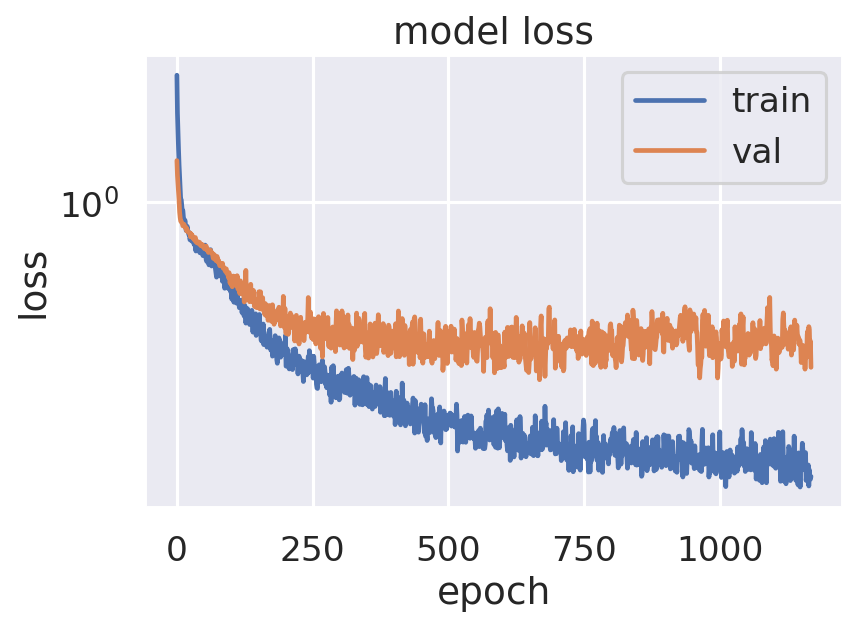

In [31]:
#https://machinelearningmastery.com/display-deep-learning-model-training-history-in-keras/
plt.figure(dpi=150)
plt.plot(model.history.history['loss'])
plt.plot(model.history.history['val_loss'])
plt.title('model loss')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train', 'val'])
plt.yscale("log")
plt.show()

In [32]:
#get the neural networks prediction (with validation dataset)
Y_nn_test = model(X_val, training = False)
Y_emu_test = np.exp(Y_std * Y_nn_test + Y_mean) - 1e-5

In [33]:
# To test how it works with training data (pretty well)
# Y_nn_test = model(X_train, training = False)
# Y_emu_test = np.exp(Y_std * Y_nn_test + Y_mean) - 1e-5

In [34]:
y_true = np.exp(Y_std * Y_val + Y_mean) - 1e-5

In [35]:
time_feature = antesonic_time.pop("time")

Text(0, 0.5, 'y_true - y_predict')

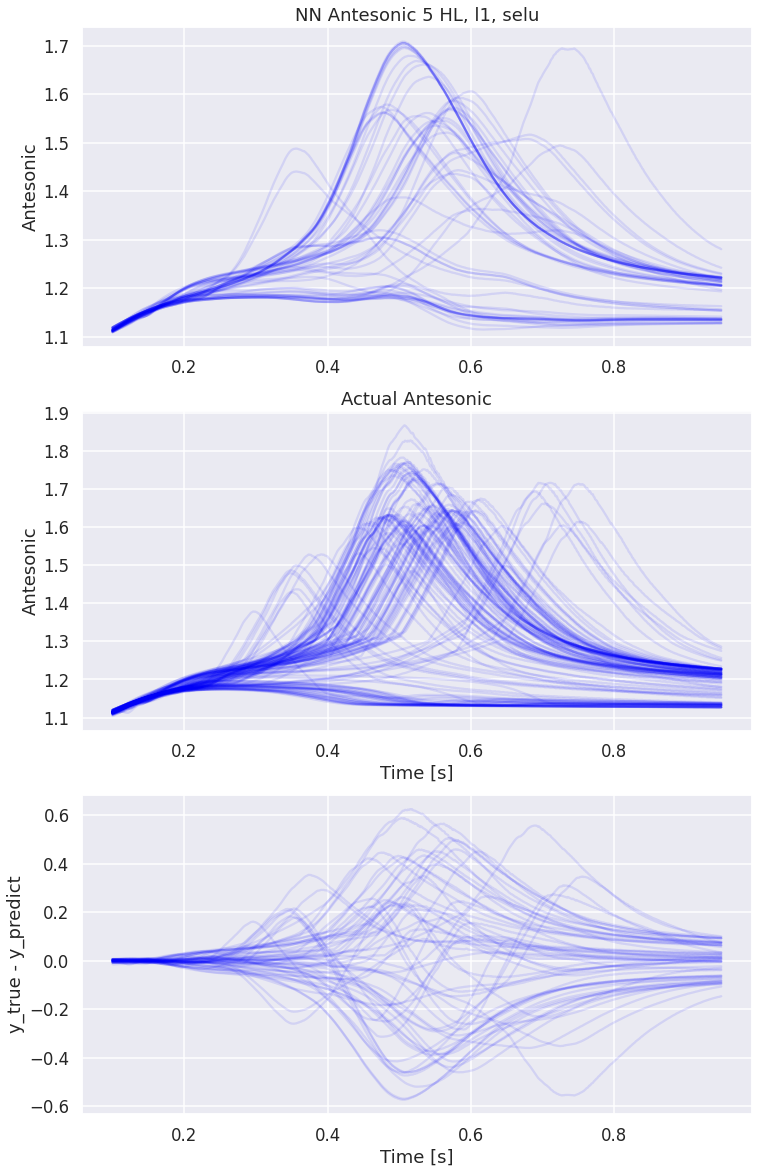

In [36]:
#plot the results
%matplotlib inline

plt.figure(figsize = (12,20))


plt.subplot(3,1,1)
for i in range(len(Y_emu_test)):
    plt.plot(time_feature, Y_emu_test[i], c = "blue", alpha = .1)
    
plt.ylabel("Antesonic")
plt.title("NN Antesonic 5 HL, l1, selu")


plt.subplot(3,1,2)
y_true = np.exp(Y_std * Y_train + Y_mean) - 1e-5
for i in range(len(y_true)):
    plt.plot(time_feature,y_true[i], color = "blue", alpha = .1)
    
plt.xlabel("Time [s]")
plt.ylabel("Antesonic")
plt.title("Actual Antesonic")

plt.subplot(3,1,3)

for y_t, y_p in zip(y_true, Y_emu_test):
    plt.plot(time_feature, y_t - y_p, color = "blue", alpha = .1)
    
plt.xlabel("Time [s]")
plt.ylabel("y_true - y_predict")

In [37]:
NN_max_turb = np.max(Y_emu_test, axis = 1)

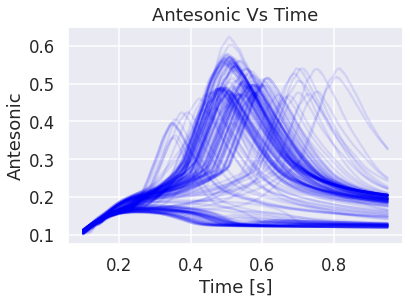

In [39]:
max_turb = np.zeros(200)
for i,j in enumerate(antesonic_time.columns[1:]):
        max_turb[i] += np.max(antesonic_time[j])
        plt.plot(time_feature,antesonic_time[j], color = "blue", alpha = .1)
        plt.title("Antesonic Vs Time")
        plt.xlabel("Time [s]")
        plt.ylabel("Antesonic")

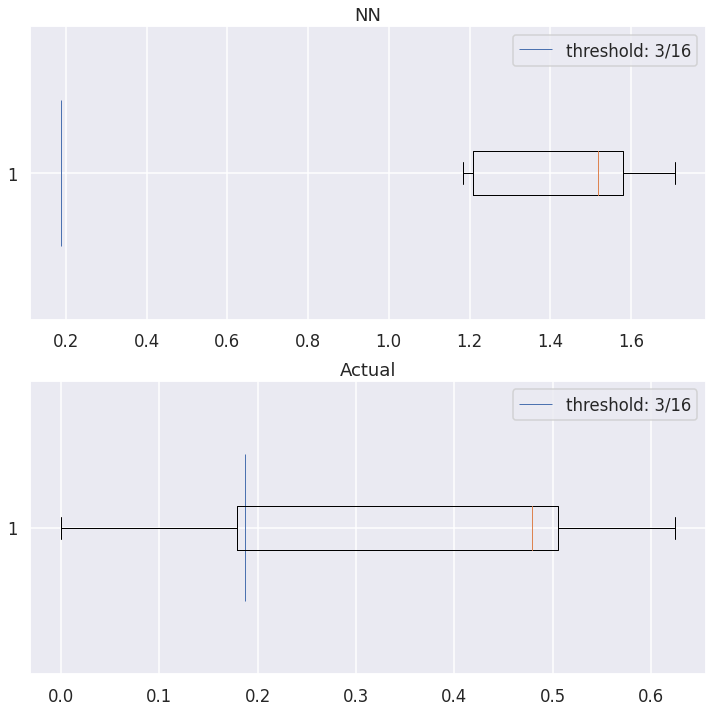

In [40]:
plt.figure(figsize = (10,10))

plt.subplot(2,1,1)
plt.title("NN")
plt.boxplot(NN_max_turb, vert = False)
plt.vlines(x = 3/16, ymin = .75, ymax = 1.25, lw = 1, label = "threshold: 3/16")
plt.legend()
plt.plot()

plt.subplot(2,1,2)
plt.title("Actual")
plt.boxplot(max_turb, vert = False)
plt.vlines(x = 3/16, ymin = .75, ymax = 1.25, lw = 1, label = "threshold: 3/16")
plt.legend()
plt.plot()

plt.tight_layout()

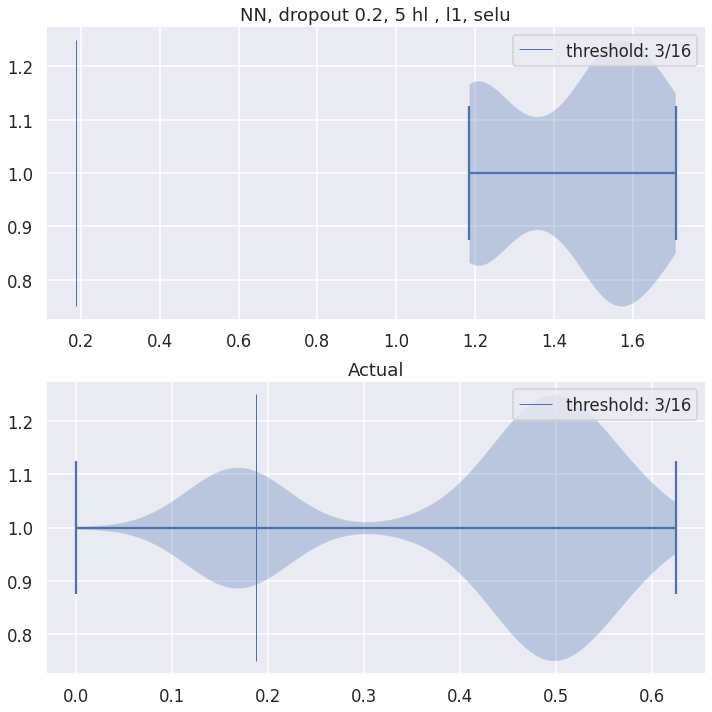

In [41]:
plt.figure(figsize = (10,10))

plt.subplot(2,1,1)
plt.title("NN, dropout 0.2, 5 hl , l1, selu")
plt.violinplot(NN_max_turb, vert = False)
plt.vlines(x = 3/16, ymin = .75, ymax = 1.25, lw = 1, label = "threshold: 3/16")
plt.legend()
plt.plot()

plt.subplot(2,1,2)
plt.title("Actual")
plt.violinplot(max_turb, vert = False)
plt.vlines(x = 3/16, ymin = .75, ymax = 1.25, lw = 1, label = "threshold: 3/16")
plt.legend()
plt.plot()

plt.tight_layout()

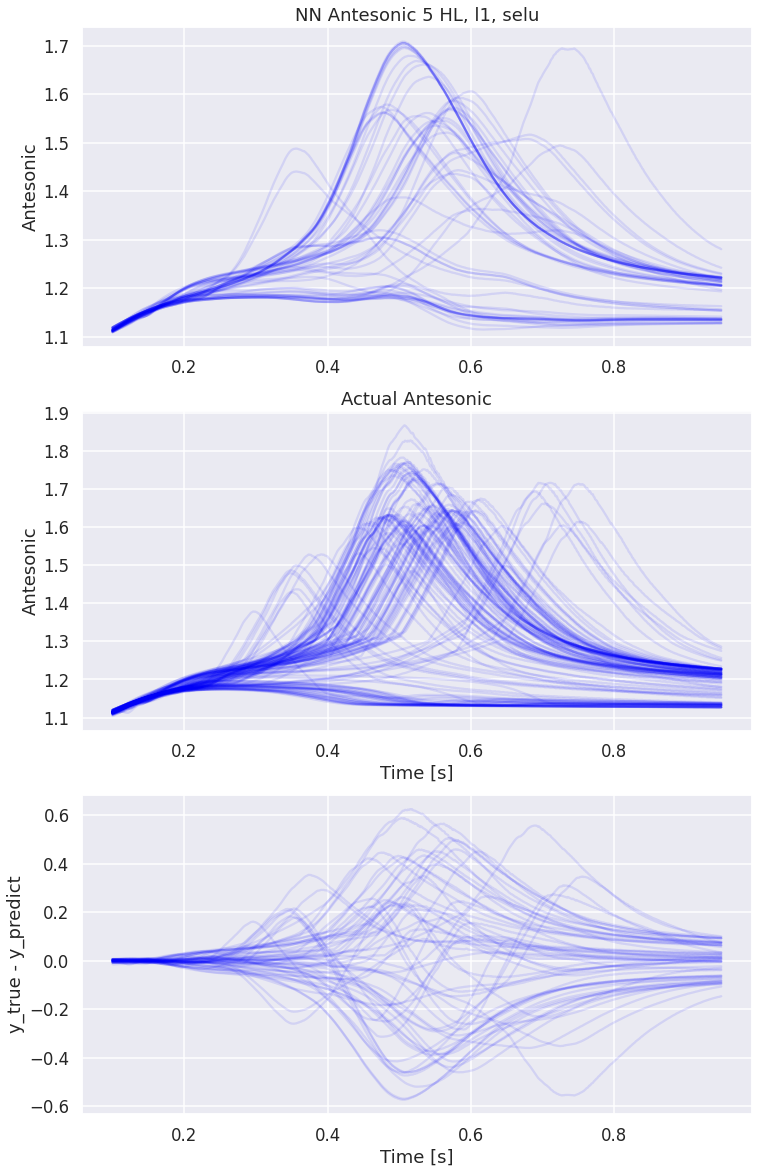

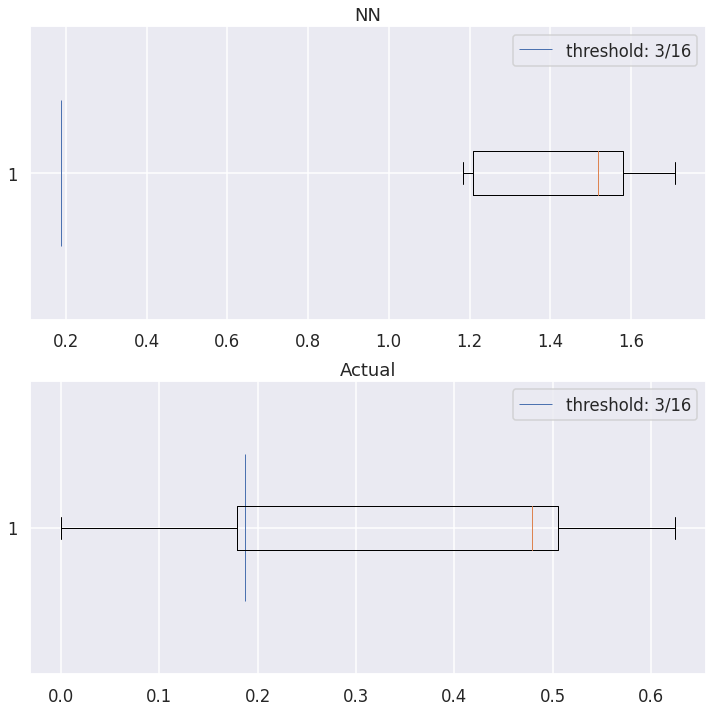

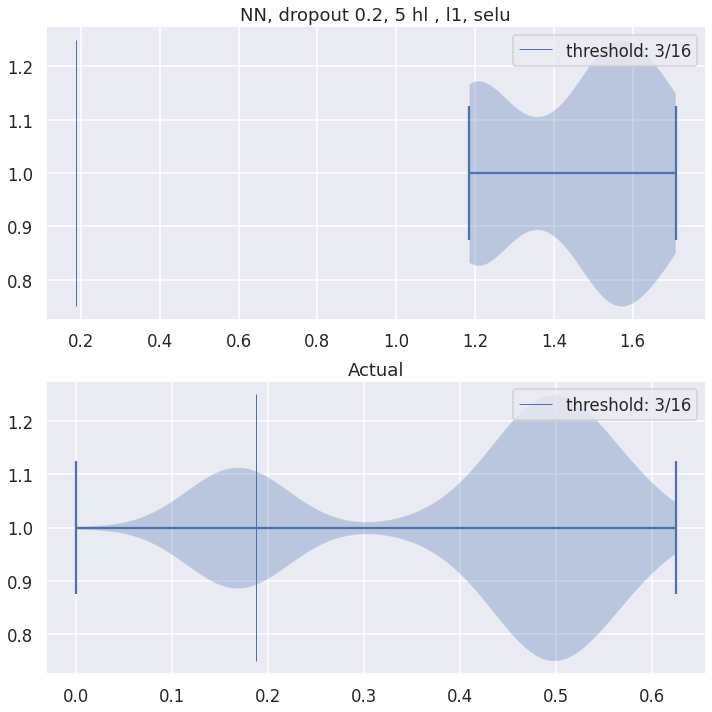

In [42]:
#get the neural networks prediction (with validation dataset)
Y_nn_test = model(X_val, training = False)
Y_emu_test = np.exp(Y_std * Y_nn_test + Y_mean) - 1e-5

# To test how it works with training data (pretty well)
# Y_nn_test = model(X_train, training = False)
# Y_emu_test = np.exp(Y_std * Y_nn_test + Y_mean) - 1e-5

y_true, Y_emu_test

#plot the results
%matplotlib inline

plt.figure(figsize = (12,20))


plt.subplot(3,1,1)
for i in range(len(Y_emu_test)):
    plt.plot(time_feature, Y_emu_test[i], c = "blue", alpha = .1)
    
plt.ylabel("Antesonic")
plt.title("NN Antesonic 5 HL, l1, selu")


plt.subplot(3,1,2)
y_true = np.exp(Y_std * Y_train + Y_mean) - 1e-5
for i in range(len(y_true)):
    plt.plot(time_feature,y_true[i], color = "blue", alpha = .1)
    
plt.xlabel("Time [s]")
plt.ylabel("Antesonic")
plt.title("Actual Antesonic")

plt.subplot(3,1,3)

for y_t, y_p in zip(y_true, Y_emu_test):
    plt.plot(time_feature, y_t - y_p, color = "blue", alpha = .1)
    
plt.xlabel("Time [s]")
plt.ylabel("y_true - y_predict")

NN_max_turb = np.max(Y_emu_test, axis = 1)

plt.figure(figsize = (10,10))

plt.subplot(2,1,1)
plt.title("NN")
plt.boxplot(NN_max_turb, vert = False)
plt.vlines(x = 3/16, ymin = .75, ymax = 1.25, lw = 1, label = "threshold: 3/16")
plt.legend()
plt.plot()

plt.subplot(2,1,2)
plt.title("Actual")
plt.boxplot(max_turb, vert = False)
plt.vlines(x = 3/16, ymin = .75, ymax = 1.25, lw = 1, label = "threshold: 3/16")
plt.legend()
plt.plot()

plt.tight_layout()

plt.figure(figsize = (10,10))

plt.subplot(2,1,1)
plt.title("NN, dropout 0.2, 5 hl , l1, selu")
plt.violinplot(NN_max_turb, vert = False)
plt.vlines(x = 3/16, ymin = .75, ymax = 1.25, lw = 1, label = "threshold: 3/16")
plt.legend()
plt.plot()

plt.subplot(2,1,2)
plt.title("Actual")
plt.violinplot(max_turb, vert = False)
plt.vlines(x = 3/16, ymin = .75, ymax = 1.25, lw = 1, label = "threshold: 3/16")
plt.legend()
plt.plot()

plt.tight_layout()